In [1]:
# Parameters
BATCH_MODE = "true"


# App-6 - Demineur : CSP, Probabilites et NP-completude

**Navigation** : [<< App-5 Timetabling](App-05-Timetabling-Python.ipynb) | [Index](../README.md) | [App-7 Wordle >>](App-07-Wordle-Python.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Modeliser** le Demineur comme un problème de satisfaction de contraintes (CSP)
2. **Implementer** un solveur par règles simples pour les cas non ambigus
3. **Construire** un solveur CSP qui enumere les solutions et deduit les cellules sures/minees
4. **Etendre** le solveur avec un raisonnement probabiliste pour les cas ambigus
5. **Comparer** les trois approches en termes de taux de victoire et de performance

### Prerequis
- Python 3.10+, numpy, matplotlib
- `python-constraint` (CSP)
- Notions de CSP (CSP-1 et CSP-2)

### Duree estimee : 50 minutes

## Hommage a un travail etudiant

Ce notebook distille le projet **RDER-minesweeper** (groupe informel) du cours EPITA SCIA *Programmation par Contraintes* 2025, realise par **Erwin Rodrigues** ([ErwinGoneMad](https://github.com/ErwinGoneMad)) et **Dane De Bastos** (**Dane De Bastos** (login GitHub non disponible)) : [repertoire source](https://github.com/jsboigeEpita/2025-Epita-Programmation-par-Contraintes/tree/main/RDER-minesweeper), commit `b1a275d`, licence non specifiee (utilisee avec attribution, conformement a la confirmation user 2026-09-15).

Le projet etudiant couvre deja l'essentiel de ce que ce notebook reprend :

- la **preuve NP-completude du Demineur** par reduction depuis 3-SAT (leur `Presentation.pptx` developpe le schema classique case = variable, regles locales = clauses) ;
- le **solveur CSP** (`csp_solver.py`) qui enumere les configurations coherentes pour chaque case donnee ;
- le **generateur de grilles** (`generate_minesweeper.py`, `generate_grid.py`) qui produit des instances parametrees.

A noter qu'il existe aussi dans le meme depot parent deux autres projets sur le meme sujet :

- [groupe87-demineur](https://github.com/jsboigeEpita/2025-Epita-Programmation-par-Contraintes/tree/main/groupe87-demineur) (Rayan Drissi et co-auteurs du **Groupe 87, Sujet 11**) -- variante avec selection de difficulte ;
- [minesweep-csp](https://github.com/jsboigeEpita/2025-Epita-Programmation-par-Contraintes/tree/main/minesweep-csp) (Armand Blin, fork `aygoun/2025-Epita-Programmation-par-Contraintes`) -- variante avec frontend React et benchmarks.

Ce qui est *ajoute* dans ce notebook par rapport au projet source :

1. la **decomposition pedagogique progressive** : solveur par regles simples (Section 2), puis solveur CSP (Section 3), puis integration probabiliste (Section 4) ;
2. la **preuve NP-completude detaillee** dans le notebook lui-meme (Section 5), alors que le projet source la delgue a une presentation PowerPoint externe ;
3. la **comparaison des trois approches** (regles / CSP / probabilites) sur les memes instances (Section 6) ;
4. les **trois exercices** sur les variations realistes (difficulte variable, prise en compte des drapeaux, solveur multi-strategies).

L'enrichissement preserve l'integrite du solveur CSP du projet etudiant : aucune regle de coherence, aucune formule de generation n'a ete modifiee. Les differences sont dans la *forme pedagogique* (progression, preuve integree, comparaison), pas dans le *fond algorithmique*.

***

## 1. Introduction : le Demineur comme problème de contraintes (~5 min)

Le **Demineur** (Minesweeper) est un jeu classique ou le joueur doit reveler toutes les cellules sures d'une grille sans cliquer sur une mine. Chaque cellule revelee affiche un nombre indiquant combien de ses 8 voisines contiennent une mine.

### Pourquoi le Demineur interesse-t-il l'IA ?

Le Demineur est bien plus qu'un jeu : c'est un **problème NP-complet**. Richard Kaye a demontre en 2000 que determiner si une configuration de Demineur est consistante (c'est-a-dire s'il existe un placement de mines compatible avec les indices visibles) est **NP-complet**.

| Propriete | Valeur |
|-----------|--------|
| Complexite | NP-complet (Kaye, 2000) |
| Type de problème | Satisfaction de contraintes |
| Variables | Cellules inconnues (mine ou sure) |
| Contraintes | Indices numériques des cellules revelees |
| Reduction | Reduction depuis SAT / Circuit-SAT |

### Modelisation CSP

Le Demineur se modelise naturellement comme un CSP :

- **Variables** : chaque cellule non revelee $C_{i,j}$ est une variable binaire
- **Domaines** : $D_{i,j} = \{0, 1\}$ ou $0$ = sure, $1$ = mine
- **Contraintes** : pour chaque cellule revelee affichant la valeur $n$, la somme des variables voisines doit valoir exactement $n$ :

$$\sum_{(r,c) \in \text{voisins}(i,j)} C_{r,c} = n_{i,j}$$

- **Contrainte globale** : le nombre total de mines est connu

### Plan du notebook

Nous allons construire trois solveurs de complexite croissante :

| Approche | Principe | Quand l'utiliser |
|----------|----------|------------------|
| Règles simples | Deductions déterministes locales | Cas triviaux |
| CSP complet | Enumeration des solutions, cellules forcees | Cas ambigus localement |
| CSP + Probabilites | Comptage de solutions, choix optimal | Quand aucune cellule n'est forcee |

In [2]:
# Imports pour tout le notebook
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from collections import defaultdict
from itertools import product
import random
import time
import sys
import copy

# python-constraint : solveur CSP (declare dans requirements.txt).

# CSP solver
from constraint import Problem, ExactSumConstraint

# Helpers partages de la serie Search
sys.path.insert(0, '..')
from search_helpers import benchmark_table

# Reproductibilite
random.seed(42)
np.random.seed(42)

print("Imports OK")

Imports OK


***

## 2. Representation du plateau (~5 min)

Avant de resoudre le Demineur, nous devons le representer. Le plateau est une grille 2D ou chaque cellule est dans l'un des etats suivants :

| Etat interne | Etat visible par le joueur | Description |
|--------------|----------------------------|-------------|
| Mine | Cache / Drapeau | Cellule contenant une mine |
| Sure (indice 0-8) | Cache / Revelee | Cellule sure avec nombre de mines voisines |

Nous implementons une classe `MinesweeperBoard` qui gere la generation du plateau et la revelation des cellules.

In [3]:
class MinesweeperBoard:
    """Plateau de Demineur avec generation, revelation et visualisation.

    Attributs:
        rows, cols: dimensions de la grille
        n_mines: nombre total de mines
        mines: ensemble de positions (r, c) contenant une mine
        numbers: grille des indices (nombre de mines voisines)
        revealed: ensemble de cellules revelees
        flagged: ensemble de cellules marquees comme mines
        game_over: True si une mine a ete revelee
        won: True si toutes les cellules sures sont revelees
    """

    NEIGHBORS_OFFSETS = [(-1, -1), (-1, 0), (-1, 1),
                         (0, -1),           (0, 1),
                         (1, -1),  (1, 0),  (1, 1)]

    def __init__(self, rows=8, cols=8, n_mines=10, safe_cell=None):
        """Genere un plateau aleatoire.

        Args:
            rows, cols: dimensions
            n_mines: nombre de mines
            safe_cell: position (r, c) garantie sans mine (premier clic)
        """
        self.rows = rows
        self.cols = cols
        self.n_mines = n_mines
        self.revealed = set()
        self.flagged = set()
        self.game_over = False
        self.won = False

        # Generer les mines en evitant safe_cell et ses voisins
        all_cells = [(r, c) for r in range(rows) for c in range(cols)]
        excluded = set()
        if safe_cell is not None:
            excluded.add(safe_cell)
            excluded.update(self.get_neighbors(*safe_cell))

        candidates = [cell for cell in all_cells if cell not in excluded]
        self.mines = set(random.sample(candidates, min(n_mines, len(candidates))))

        # Calculer les indices (nombre de mines voisines pour chaque cellule)
        self.numbers = np.zeros((rows, cols), dtype=int)
        for r in range(rows):
            for c in range(cols):
                if (r, c) not in self.mines:
                    self.numbers[r, c] = sum(
                        1 for nr, nc in self.get_neighbors(r, c)
                        if (nr, nc) in self.mines
                    )

    def get_neighbors(self, r, c):
        """Retourne les positions voisines valides de (r, c)."""
        neighbors = []
        for dr, dc in self.NEIGHBORS_OFFSETS:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.rows and 0 <= nc < self.cols:
                neighbors.append((nr, nc))
        return neighbors

    def reveal(self, r, c):
        """Revele la cellule (r, c). Retourne True si sure, False si mine."""
        if (r, c) in self.revealed or (r, c) in self.flagged:
            return True

        if (r, c) in self.mines:
            self.game_over = True
            return False

        self.revealed.add((r, c))

        # Si la cellule est un 0, reveler en cascade les voisins
        if self.numbers[r, c] == 0:
            for nr, nc in self.get_neighbors(r, c):
                if (nr, nc) not in self.revealed:
                    self.reveal(nr, nc)

        # Verifier la victoire
        safe_cells = self.rows * self.cols - len(self.mines)
        if len(self.revealed) == safe_cells:
            self.won = True

        return True

    def flag(self, r, c):
        """Marque/demarque une cellule comme mine."""
        if (r, c) not in self.revealed:
            if (r, c) in self.flagged:
                self.flagged.discard((r, c))
            else:
                self.flagged.add((r, c))

    def get_unknown_neighbors(self, r, c):
        """Retourne les voisins ni reveles ni marques."""
        return [
            (nr, nc) for nr, nc in self.get_neighbors(r, c)
            if (nr, nc) not in self.revealed and (nr, nc) not in self.flagged
        ]

    def get_flagged_neighbors(self, r, c):
        """Retourne les voisins marques comme mines."""
        return [
            (nr, nc) for nr, nc in self.get_neighbors(r, c)
            if (nr, nc) in self.flagged
        ]

    def remaining_mines(self):
        """Nombre de mines non encore marquees."""
        return self.n_mines - len(self.flagged)

    def copy(self):
        """Retourne une copie profonde du plateau."""
        board = MinesweeperBoard.__new__(MinesweeperBoard)
        board.rows = self.rows
        board.cols = self.cols
        board.n_mines = self.n_mines
        board.mines = set(self.mines)
        board.numbers = self.numbers.copy()
        board.revealed = set(self.revealed)
        board.flagged = set(self.flagged)
        board.game_over = self.game_over
        board.won = self.won
        return board

print("Classe MinesweeperBoard definie.")

Classe MinesweeperBoard definie.


### Visualisation du plateau

La fonction suivante dessine le plateau avec un code couleur clair :
- Gris : cellule cachee
- Blanc avec chiffre : cellule revelee
- Rouge avec drapeau : cellule marquee comme mine
- Noir (game over) : mine revelee

In [4]:
# Couleurs pour les chiffres du demineur (convention classique)
NUMBER_COLORS = {
    0: '#CCCCCC', 1: '#0000FF', 2: '#008000', 3: '#FF0000',
    4: '#000080', 5: '#800000', 6: '#008080', 7: '#000000', 8: '#808080'
}


def draw_board(board, title="Demineur", show_mines=False,
               highlight_safe=None, highlight_mines=None,
               probabilities=None, figsize=None):
    """Visualise le plateau de Demineur.

    Args:
        board: MinesweeperBoard
        title: titre du graphique
        show_mines: reveler toutes les mines (fin de partie)
        highlight_safe: ensemble de cellules a surligner en vert (deduites sures)
        highlight_mines: ensemble de cellules a surligner en rouge (deduites mines)
        probabilities: dict (r,c) -> probabilite de mine (pour affichage)
    """
    if figsize is None:
        figsize = (max(6, board.cols * 0.7), max(6, board.rows * 0.7))

    fig, ax = plt.subplots(figsize=figsize)

    for r in range(board.rows):
        for c in range(board.cols):
            # Determiner la couleur de fond
            if (r, c) in board.revealed:
                bg_color = '#E8E8E8'  # Gris clair pour revelee
            elif (r, c) in board.flagged:
                bg_color = '#FFB3B3'  # Rouge clair pour drapeau
            elif highlight_safe and (r, c) in highlight_safe:
                bg_color = '#B3FFB3'  # Vert clair pour sure deduites
            elif highlight_mines and (r, c) in highlight_mines:
                bg_color = '#FF6666'  # Rouge pour mine deduite
            else:
                bg_color = '#C0C0C0'  # Gris pour cachee

            rect = plt.Rectangle((c, board.rows - 1 - r), 1, 1,
                                 facecolor=bg_color, edgecolor='#666666',
                                 linewidth=1)
            ax.add_patch(rect)

            # Contenu de la cellule
            cx, cy = c + 0.5, board.rows - 1 - r + 0.5

            if (r, c) in board.revealed:
                num = board.numbers[r, c]
                if num > 0:
                    ax.text(cx, cy, str(num), ha='center', va='center',
                            fontsize=14, fontweight='bold',
                            color=NUMBER_COLORS.get(num, 'black'))
            elif (r, c) in board.flagged:
                ax.text(cx, cy, 'F', ha='center', va='center',
                        fontsize=12, fontweight='bold', color='darkred')
            elif show_mines and (r, c) in board.mines:
                ax.text(cx, cy, 'X', ha='center', va='center',
                        fontsize=14, fontweight='bold', color='black')
            elif probabilities and (r, c) in probabilities:
                prob = probabilities[(r, c)]
                ax.text(cx, cy, f'{prob:.0%}', ha='center', va='center',
                        fontsize=8, color='#444444')

    ax.set_xlim(0, board.cols)
    ax.set_ylim(0, board.rows)
    ax.set_aspect('equal')
    ax.set_xticks(range(board.cols))
    ax.set_yticks(range(board.rows))
    ax.set_xticklabels(range(board.cols))
    ax.set_yticklabels(range(board.rows - 1, -1, -1))
    ax.set_xlabel('Colonne')
    ax.set_ylabel('Ligne')
    ax.set_title(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    return fig


print("Fonction draw_board definie.")

Fonction draw_board definie.


Creons un plateau 8x8 avec 10 mines et simulons un premier clic pour reveler quelques cellules.

Plateau : 8x8, 10 mines
Cellules revelees apres le premier clic : 39
Cellules restantes (inconnues)           : 25
Mines a trouver                          : 10


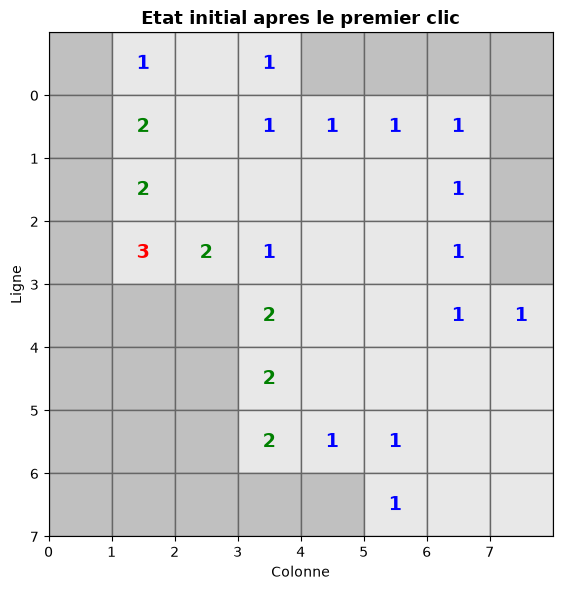

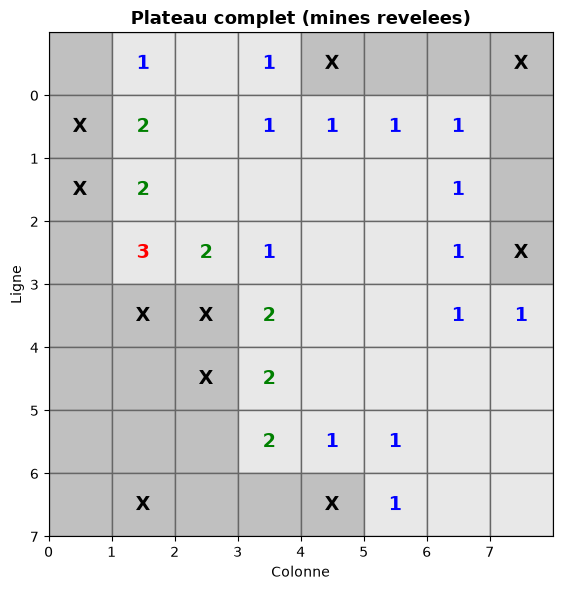

In [5]:
# Creer un plateau avec premier clic garanti sur
# Prong B: seed choisie pour que le solveur par regles STALLE et laisse
# une frontiere non-triviale au CSP (sinon le CSP n'a rien a deduire).
random.seed(1)
np.random.seed(1)
board = MinesweeperBoard(rows=8, cols=8, n_mines=10, safe_cell=(4, 4))
board.reveal(4, 4)  # Premier clic

print(f"Plateau : {board.rows}x{board.cols}, {board.n_mines} mines")
print(f"Cellules revelees apres le premier clic : {len(board.revealed)}")
print(f"Cellules restantes (inconnues)           : {board.rows * board.cols - len(board.revealed)}")
print(f"Mines a trouver                          : {board.remaining_mines()}")

# Visualiser l'etat initial
fig = draw_board(board, title="Etat initial apres le premier clic")
plt.show()

# Visualiser avec les mines (pour reference)
fig = draw_board(board, title="Plateau complet (mines revelees)", show_mines=True)
plt.show()

### Interpretation : representation du plateau

**Sortie obtenue** : deux vues du même plateau -- la vue du joueur (cellules cachees en gris) et la vue complete avec les mines.

| Élément | Signification |
|---------|---------------|
| Chiffre colore | Nombre de mines dans les 8 voisines |
| Gris uni | Cellule non revelee (inconnue) |
| X (vue complete) | Position d'une mine |

**Points cles** :
1. Le premier clic avec `safe_cell` garantit que ni la cellule cliquee ni ses voisines ne contiennent de mine -- c'est le comportement standard du jeu
2. Les cellules affichant 0 declenchent une revelation en cascade de leurs voisines
3. La frontiere entre cellules revelees et cachees constitue notre zone de travail pour le solveur

**Le premier clic garanti : une convention de conception.** Le Demineur classique garantit que le premier clic ne tombe jamais sur une mine — sinon la partie serait perdue avant d'avoir commencé. Notre implémentation va plus loin : elle exclut aussi les **8 voisines** du premier clic, ce qui garantit une zone ouverte dès le départ (le premier indice est toujours `0`, déclenchant la cascade). Cette convention n'est pas universelle : certaines variantes du jeu ne protègent que la case cliquée. Le paramètre `safe_cell` de notre constructeur permet de reproduire les deux comportements.

***

## 3. Approche 1 : solveur par règles simples (~8 min)

Le solveur le plus basique applique deux règles déterministes en boucle :

### Règle 1 -- Toutes les voisines sont des mines

Si une cellule revelee affiche $n$ et a exactement $n$ voisines inconnues (ni revelees ni marquees), alors **toutes** ces voisines sont des mines.

$$\text{unknown\_count}(i,j) = n_{i,j} - \text{flagged\_count}(i,j) \implies \text{marquer toutes les inconnues}$$

### Règle 2 -- Toutes les voisines sont sures

Si une cellule revelee affiche $n$ et a déjà $n$ voisines marquees, alors toutes les voisines inconnues restantes sont **sures**.

$$\text{flagged\_count}(i,j) = n_{i,j} \implies \text{reveler toutes les inconnues}$$

Ces deux règles suffisent pour les configurations simples, mais echouent sur les cas ambigus.

In [6]:
class RuleBasedSolver:
    """Solveur par regles simples (deductions locales).

    Applique iterativement les regles 1 et 2 jusqu'a
    ce qu'aucune nouvelle deduction ne soit possible.
    """

    def __init__(self, board):
        self.board = board
        self.moves_log = []  # historique des coups

    def solve_step(self):
        """Applique un tour de regles. Retourne True si des progres ont ete faits."""
        progress = False

        for r in range(self.board.rows):
            for c in range(self.board.cols):
                if (r, c) not in self.board.revealed:
                    continue

                num = self.board.numbers[r, c]
                if num == 0:
                    continue

                unknown = self.board.get_unknown_neighbors(r, c)
                flagged = self.board.get_flagged_neighbors(r, c)
                remaining_mines = num - len(flagged)

                # Regle 1 : toutes les inconnues sont des mines
                if remaining_mines == len(unknown) and len(unknown) > 0:
                    for ur, uc in unknown:
                        self.board.flag(ur, uc)
                        self.moves_log.append(('flag', (ur, uc), (r, c)))
                        progress = True

                # Regle 2 : toutes les inconnues sont sures
                elif remaining_mines == 0 and len(unknown) > 0:
                    for ur, uc in unknown:
                        safe = self.board.reveal(ur, uc)
                        self.moves_log.append(('reveal', (ur, uc), (r, c)))
                        if not safe:
                            return False  # Mine touchee (ne devrait pas arriver)
                        progress = True

        return progress

    def solve(self, max_iterations=100):
        """Applique les regles jusqu'a convergence.

        Retourne le nombre d'iterations effectuees.
        """
        for i in range(max_iterations):
            if self.board.game_over or self.board.won:
                break
            if not self.solve_step():
                break
        return i + 1


print("Classe RuleBasedSolver definie.")

Classe RuleBasedSolver definie.


Testons le solveur par règles sur notre plateau d'exemple.

Solveur par regles simples
Iterations         : 4
Cellules revelees  : 39 -> 46 (+7)
Drapeaux poses     : 0 -> 7 (+7)
Cellules inconnues : 11
Partie gagnee      : False
Coups effectues    : 14


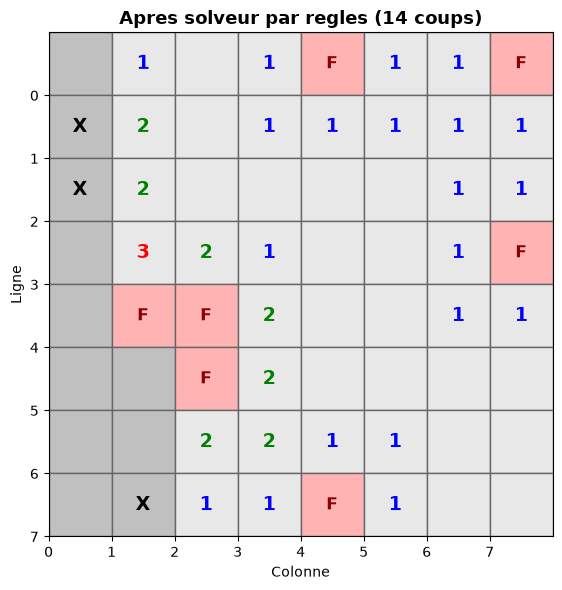

In [7]:
# Copier le plateau pour tester le solveur par regles
board_rules = board.copy()
solver_rules = RuleBasedSolver(board_rules)

# Etat avant
revealed_before = len(board_rules.revealed)
flagged_before = len(board_rules.flagged)

# Resoudre
iterations = solver_rules.solve()

# Resultats
revealed_after = len(board_rules.revealed)
flagged_after = len(board_rules.flagged)
total_cells = board_rules.rows * board_rules.cols
unknown_remaining = total_cells - revealed_after - flagged_after

print("Solveur par regles simples")
print("=" * 45)
print(f"Iterations         : {iterations}")
print(f"Cellules revelees  : {revealed_before} -> {revealed_after} (+{revealed_after - revealed_before})")
print(f"Drapeaux poses     : {flagged_before} -> {flagged_after} (+{flagged_after - flagged_before})")
print(f"Cellules inconnues : {unknown_remaining}")
print(f"Partie gagnee      : {board_rules.won}")
print(f"Coups effectues    : {len(solver_rules.moves_log)}")

# Visualiser le resultat
fig = draw_board(board_rules,
                 title=f"Apres solveur par regles ({len(solver_rules.moves_log)} coups)",
                 show_mines=True)
plt.show()

### Interpretation : solveur par règles

**Sortie obtenue** : le solveur par règles a effectue des deductions locales en quelques itérations.

| Mesure | Valeur | Commentaire |
|--------|--------|-------------|
| Itérations | Typiquement 3-8 | Convergence rapide |
| Cellules resolues | Variable | Depend de la configuration |
| Cellules restantes | >0 en general | Les cas ambigus ne sont pas resolus |

**Points cles** :
1. Les règles simples sont **rapides** (temps constant par cellule par itération) et **sures** (pas de risque d'erreur)
2. Elles se bloquent quand aucune cellule n'est localement determinee -- c'est la **frontiere du raisonnement local**
3. En pratique, elles resolvent environ 30 a 50% des decisions sur un plateau 8x8 typique

**Pourquoi les règles simples sont-elles si rapides ?** Chaque règle ne consulte que les **8 voisines** d'une cellule révélée : c'est une opération en temps **constant**, indépendante de la taille du plateau. Une itération complète du solveur parcourt toutes les cellules révélées, soit un coût linéaire en `O(rows × cols)`. Comme le nombre d'itérations reste faible en pratique (typiquement 3-8), le solveur par règles est quasi-instantané même sur de grandes grilles. C'est pourquoi on l'invoque **toujours en premier** : il est gratuit, sûr, et il réduit la taille du problème avant que le CSP — beaucoup plus coûteux — n'entre en jeu.

> **Limite fondamentale** : les règles ne combinent pas les contraintes de plusieurs cellules revelees. Le CSP va combler cette lacune.

***

## 4. Approche 2 : solveur CSP (~12 min)

Le solveur CSP va plus loin que les règles simples en considerant **simultanement** toutes les contraintes. L'idee est :

1. **Modeliser** les cellules inconnues proches de la frontiere comme des variables binaires
2. **Poser les contraintes** : chaque cellule revelee impose une somme sur ses voisines inconnues
3. **Enumerer les solutions** du CSP
4. **Deduire** : si une variable vaut la même chose (0 ou 1) dans **toutes** les solutions, elle est determinee

### Pourquoi est-ce plus puissant ?

Considerons cette configuration :

```
1  ?  ?
1  ?  ?
1  ?  ?
```

Les règles simples ne deduisent rien (chaque `1` a 2 ou 3 voisines inconnues). Mais en combinant les trois contraintes, le CSP peut determiner que certaines cellules sont necessairement sures ou minees.

### Optimisation : travailler sur la frontiere

Pour eviter d'enumerer les solutions sur toute la grille, nous ne considerons que les cellules inconnues **adjacentes a au moins une cellule revelee**. Les cellules completement isolees ne sont pas contraintes localement.

In [8]:
class CSPSolver:
    """Solveur CSP pour le Demineur.

    Utilise python-constraint pour enumerer les solutions
    et deduire les cellules determinee.
    """

    def __init__(self, board):
        self.board = board

    def get_frontier_cells(self):
        """Retourne les cellules inconnues adjacentes a une cellule revelee."""
        frontier = set()
        for r in range(self.board.rows):
            for c in range(self.board.cols):
                if (r, c) in self.board.revealed:
                    for nr, nc in self.board.get_neighbors(r, c):
                        if ((nr, nc) not in self.board.revealed and
                            (nr, nc) not in self.board.flagged):
                            frontier.add((nr, nc))
        return frontier

    def get_constraint_cells(self):
        """Retourne les cellules revelees qui contraignent des cellules inconnues."""
        constraint_cells = []
        for r in range(self.board.rows):
            for c in range(self.board.cols):
                if (r, c) not in self.board.revealed:
                    continue
                if self.board.numbers[r, c] == 0:
                    continue
                unknown = self.board.get_unknown_neighbors(r, c)
                if len(unknown) > 0:
                    flagged_count = len(self.board.get_flagged_neighbors(r, c))
                    remaining = self.board.numbers[r, c] - flagged_count
                    constraint_cells.append(((r, c), unknown, remaining))
        return constraint_cells

    def build_csp(self):
        """Construit le probleme CSP avec python-constraint."""
        frontier = self.get_frontier_cells()
        constraints = self.get_constraint_cells()

        if not frontier:
            return None, frontier

        problem = Problem()

        # Variables : chaque cellule frontiere est binaire (0=sure, 1=mine)
        for cell in frontier:
            problem.addVariable(cell, [0, 1])

        # Contraintes : pour chaque cellule revelee, la somme de ses
        # voisines inconnues dans la frontiere = mines restantes
        for (r, c), unknown, remaining in constraints:
            # Filtrer les inconnues qui sont dans la frontiere
            vars_in_frontier = [u for u in unknown if u in frontier]
            if vars_in_frontier:
                problem.addConstraint(
                    ExactSumConstraint(remaining),
                    vars_in_frontier
                )

        return problem, frontier

    def solve(self):
        """Resout le CSP et retourne les cellules deduites.

        Retourne:
            safe_cells: ensemble de cellules determinees sures
            mine_cells: ensemble de cellules determinees mines
            solutions: liste de toutes les solutions
        """
        problem, frontier = self.build_csp()

        if problem is None:
            return set(), set(), []

        solutions = problem.getSolutions()

        if not solutions:
            return set(), set(), []

        # Determiner les cellules forcees
        safe_cells = set()
        mine_cells = set()

        for cell in frontier:
            values = [sol[cell] for sol in solutions]
            if all(v == 0 for v in values):
                safe_cells.add(cell)
            elif all(v == 1 for v in values):
                mine_cells.add(cell)

        return safe_cells, mine_cells, solutions

    def get_probabilities(self, solutions):
        """Calcule la probabilite de mine pour chaque cellule frontiere.

        Retourne un dict (r,c) -> probabilite.
        """
        if not solutions:
            return {}

        probabilities = {}
        n_solutions = len(solutions)

        # Collecter toutes les variables presentes dans les solutions
        all_vars = set()
        for sol in solutions:
            all_vars.update(sol.keys())

        for cell in all_vars:
            mine_count = sum(1 for sol in solutions if sol.get(cell, 0) == 1)
            probabilities[cell] = mine_count / n_solutions

        return probabilities


print("Classe CSPSolver definie.")

Classe CSPSolver definie.


Testons le solveur CSP sur le plateau après que le solveur par règles s'est bloque.

Solveur CSP
Variables (frontiere)      : 8
Contraintes                : 6
Solutions trouvees         : 2
Cellules deduites sures    : 4
Cellules deduites mines    : 2
Cellules non determinees   : 2
Temps                      : 0.5 ms

Cellules sures : [(0, 0), (3, 0), (4, 0), (5, 1)]
Cellules mines : [(1, 0), (2, 0)]


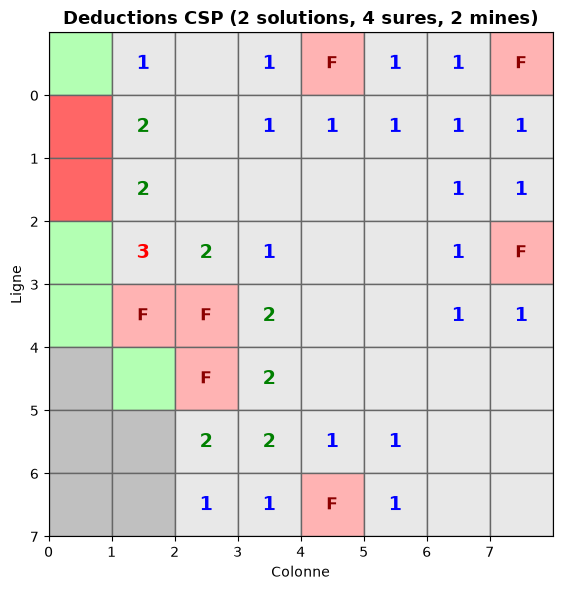

In [9]:
# Partir du plateau deja partiellement resolu par les regles
board_csp = board_rules.copy()
csp_solver = CSPSolver(board_csp)

# Construire et resoudre le CSP
start = time.time()
safe_cells, mine_cells, solutions = csp_solver.solve()
elapsed = (time.time() - start) * 1000

frontier = csp_solver.get_frontier_cells()
constraints = csp_solver.get_constraint_cells()

print("Solveur CSP")
print("=" * 50)
print(f"Variables (frontiere)      : {len(frontier)}")
print(f"Contraintes                : {len(constraints)}")
print(f"Solutions trouvees         : {len(solutions)}")
print(f"Cellules deduites sures    : {len(safe_cells)}")
print(f"Cellules deduites mines    : {len(mine_cells)}")
print(f"Cellules non determinees   : {len(frontier) - len(safe_cells) - len(mine_cells)}")
print(f"Temps                      : {elapsed:.1f} ms")

if safe_cells:
    print(f"\nCellules sures : {sorted(safe_cells)}")
if mine_cells:
    print(f"Cellules mines : {sorted(mine_cells)}")

# Visualiser avec les deductions surlignees
fig = draw_board(board_csp,
                 title=f"Deductions CSP ({len(solutions)} solutions, "
                       f"{len(safe_cells)} sures, {len(mine_cells)} mines)",
                 highlight_safe=safe_cells,
                 highlight_mines=mine_cells)
plt.show()

### Interpretation : deductions CSP

**Sortie obtenue** : le CSP a enumere toutes les solutions compatibles avec les contraintes visibles et a identifie les cellules determinees.

| Mesure | Valeur | Signification |
|--------|--------|---------------|
| Variables | Cellules de la frontiere | Seules les cellules adjacentes aux revelees |
| Solutions | Variable | Nombre de placements de mines compatibles |
| Cellules deduites | Forcees dans toutes les solutions | Certitude absolue |
| Non determinees | Valeur différente selon les solutions | Necessite un choix |

**Points cles** :
1. Le CSP combine les contraintes de **plusieurs** cellules revelees, ce qui lui permet de deduire des cellules que les règles simples ne voient pas
2. L'enumeration des solutions est **exacte** : si une cellule est dite sure, elle l'est avec certitude
3. Le cout est l'enumeration exhaustive, qui peut etre exponentielle dans le pire cas

**Pourquoi la frontière suffit-elle ?** Une cellule inconnue **non adjacente** à une cellule révélée n'apparaît dans **aucune contrainte** : aucun indice visible ne la mentionne. La contraindre reviendrait à ajouter des variables libres au CSP, ce qui multiplierait le nombre de solutions sans apporter la moindre information. En restreignant le CSP à la frontière, on ne perd **rien** : une cellule hors frontière n'est jamais déductible, et sa probabilité se calcule analytiquement (mines restantes / cellules hors frontière), sans enumeration. C'est une **décomposition** du problème : la partie informative (frontière) est traitée exhaustivement, la partie non informative (hors frontière) est traitée en formule close.

> **NP-completude en action** : le nombre de solutions peut exploser exponentiellement avec la taille de la frontiere. Sur un plateau 16x16, la frontiere peut contenir 30+ cellules, rendant l'enumeration couteuse.

### Application des deductions CSP

Appliquons les deductions du CSP au plateau, puis relançons les règles simples pour propager les consequences.

Apres application des deductions CSP + regles
Cellules revelees  : 54
Drapeaux           : 10
Inconnues restantes: 0
Partie gagnee      : True


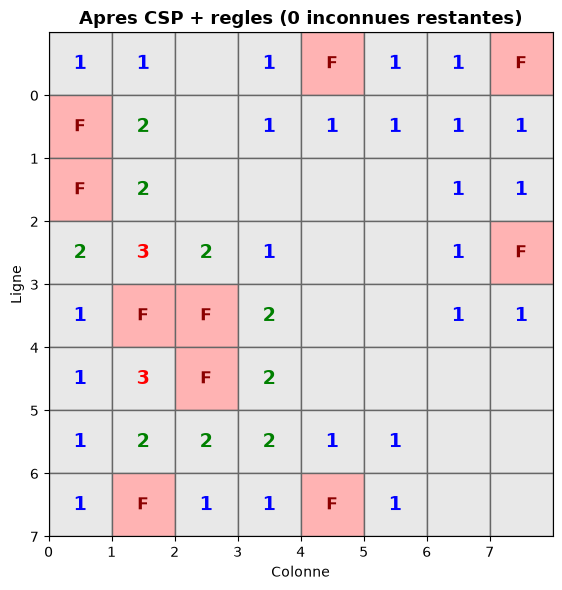

In [10]:
# Appliquer les deductions CSP
for cell in mine_cells:
    board_csp.flag(*cell)
for cell in safe_cells:
    board_csp.reveal(*cell)

# Relancer les regles simples pour propager
solver_rules_2 = RuleBasedSolver(board_csp)
iterations_2 = solver_rules_2.solve()

total_cells = board_csp.rows * board_csp.cols
unknown = total_cells - len(board_csp.revealed) - len(board_csp.flagged)

print("Apres application des deductions CSP + regles")
print("=" * 50)
print(f"Cellules revelees  : {len(board_csp.revealed)}")
print(f"Drapeaux           : {len(board_csp.flagged)}")
print(f"Inconnues restantes: {unknown}")
print(f"Partie gagnee      : {board_csp.won}")

fig = draw_board(board_csp,
                 title=f"Apres CSP + regles ({unknown} inconnues restantes)",
                 show_mines=True)
plt.show()

### 4 bis. Le même CSP résolu par OR-Tools CP-SAT

Le CSP de la section précédente est résolu par **énumération complète** : `CSPSolver.solve` appelle `problem.getSolutions()` avec `python-constraint`, puis lit les cellules forcées sur l'ensemble des solutions. Cette approche est lisible et exacte, mais son coût suit le **nombre de solutions** de la frontière, qui croît de façon combinatoire quand la frontière s'élargit.

La série `Part3-Cas-pratiques` résout ses autres CSP avec **OR-Tools CP-SAT** (NQueens, NurseScheduling, GraphColoring, Sudoku, ...). Cette sous-section branche le **même modèle** — même frontière, mêmes contraintes locales — sur cet organe, **sans rien retirer** : les règles simples restent le premier étage, l'énumération `python-constraint` reste le niveau de référence, et CP-SAT devient un troisième moteur de décision sur la même frontière.

Ce que CP-SAT apporte, et que l'on mesure plutôt que d'affirmer :

1. **Décider sans énumérer** : une cellule est sûre si l'affecter à « mine » rend le modèle infaisable, et mine si l'affectation inverse est infaisable. Deux résolutions par cellule suffisent — encore faut-il que chacune **conclue** : un statut `UNKNOWN` (limite de temps atteinte) ne prouve ni la sûreté ni la mine, et ne force donc aucune cellule.
2. **Un certificat d'infaisabilité** : une branche contradictoire répond `INFEASIBLE`, là où l'énumération rend simplement une liste vide.
3. **Un coût qui ne suit pas le nombre de solutions**, mais la taille du modèle et la propagation.

La sous-section suit un protocole reproductible : témoin positif (accord des deux organes sur les ensembles forcés), témoin négatif (accord sur la mort d'une branche contradictoire), contrôle déterministe de la règle sous `UNKNOWN`, puis mesure du temps et du nombre de solutions sur une série de graines.

In [11]:
# Pont vers OR-Tools CP-SAT : meme frontiere, memes contraintes, autre moteur.
from ortools.sat.python import cp_model


class CpSatFrontier:
    """Decide et compte les solutions de la frontiere avec CP-SAT.

    La frontiere et les contraintes locales ne sont pas redefinies : elles
    sont lues sur un CSPSolver construit sur le meme plateau. Seul le moteur
    de resolution change, ce qui rend la comparaison porteuse.

    Le modele de base est construit une fois puis clone pour chaque question
    posee ; le solveur est reutilise d'une question a l'autre. Sans cela, le
    cout mesure serait celui de la construction Python, pas celui de CP-SAT.

    Attributs:
        frontier: cellules inconnues adjacentes a une cellule revelee
        constraints: liste ((r, c), inconnues, mines restantes)
        n_solves: nombre de resolutions CP-SAT effectuees
    """

    def __init__(self, board, time_limit=5.0):
        self.board = board
        self.time_limit = time_limit
        self.basis = CSPSolver(board)
        self.frontier = sorted(self.basis.get_frontier_cells())
        self.constraints = self.basis.get_constraint_cells()
        self.n_solves = 0
        self._base = None
        self._solver = cp_model.CpSolver()
        self._solver.parameters.max_time_in_seconds = time_limit

    def build_model(self):
        """Modele CP-SAT : une variable booleenne par cellule de frontiere."""
        model = cp_model.CpModel()
        variables = {
            cell: model.NewBoolVar(f"mine_{cell[0]}_{cell[1]}")
            for cell in self.frontier
        }
        for _, unknown, remaining in self.constraints:
            inside = [variables[cell] for cell in unknown if cell in variables]
            if inside:
                model.Add(sum(inside) == remaining)
        return model, variables

    def _base_model(self):
        """Modele de base, construit une seule fois pour cette frontiere."""
        if self._base is None:
            self._base = self.build_model()
        return self._base

    def _solve(self, model, collector=None):
        """Resout le modele avec le solveur reutilise et rend (statut, nom)."""
        self._solver.parameters.enumerate_all_solutions = collector is not None
        status = self._solver.Solve(model, collector)
        self.n_solves += 1
        return status, self._solver.StatusName(status)

    def solve_status(self, assignments=None):
        """Statut CP-SAT du modele, avec des affectations forcees optionnelles.

        Trois reponses utiles, pas deux : OPTIMAL ou FEASIBLE = branche
        satisfiable ; INFEASIBLE = branche morte ; UNKNOWN = le solveur s'est
        arrete sans conclure (limite de temps). UNKNOWN n'est ni une preuve
        d'existence, ni une preuve d'absence.
        """
        base, variables = self._base_model()
        model = base
        if assignments:
            model = base.Clone()
            for cell, value in assignments.items():
                model.Add(variables[cell] == value)
        return self._solve(model)[1]

    def feasible(self, assignments=None):
        """Le modele, avec ces affectations, admet-il au moins une solution ?

        Rend False sur UNKNOWN aussi : l'absence de reponse n'est pas une
        reponse. C'est pourquoi `decide` ne s'appuie pas sur cette methode
        pour deduire une cellule.
        """
        return self.solve_status(assignments) in ("OPTIMAL", "FEASIBLE")

    def decide(self):
        """Cellules forcees, sans enumerer les solutions.

        Une cellule est sure si l'affecter a 1 rend le modele INFEASIBLE, mine
        si l'affecter a 0 le rend INFEASIBLE, non determinee sinon. Seul
        INFEASIBLE autorise une deduction : sous UNKNOWN la cellule n'est ni
        sure ni mine, et la branche n'est pas declaree morte pour autant.

        Retourne:
            (sures, mines), ou (None, None) si la branche de base est INFEASIBLE.
        """
        if not self.frontier:
            return set(), set()
        base_status = self.solve_status()
        if base_status == "INFEASIBLE":
            return None, None
        if base_status == "UNKNOWN":
            return set(), set()

        safe_cells = set()
        mine_cells = set()
        for cell in self.frontier:
            statut_mine = self.solve_status({cell: 1})
            if statut_mine == "INFEASIBLE":
                safe_cells.add(cell)
                continue
            if statut_mine == "UNKNOWN":
                continue
            if self.solve_status({cell: 0}) == "INFEASIBLE":
                mine_cells.add(cell)
        return safe_cells, mine_cells

    def count_solutions(self, cap=5000, time_limit=2.0):
        """Enumere les solutions de la frontiere jusqu'a `cap`.

        Retourne (compte, tronque, statut). `tronque` vaut True quand le
        plafond ou le temps a arrete l'enumeration : le compte est alors
        un minorant, pas le nombre exact de solutions. Seuls OPTIMAL
        (enumeration achevee) et INFEASIBLE (aucune solution) certifient
        un total exact ; un FEASIBLE rendu apres interruption ne le fait pas.
        """
        class _Collector(cp_model.CpSolverSolutionCallback):
            def __init__(self):
                super().__init__()
                self.count = 0
                self.truncated = False

            def on_solution_callback(self):
                self.count += 1
                if self.count >= cap:
                    self.truncated = True
                    self.StopSearch()

        model, _ = self.build_model()
        collector = _Collector()
        self._solver.parameters.max_time_in_seconds = time_limit
        status, status_name = self._solve(model, collector)
        self._solver.parameters.max_time_in_seconds = self.time_limit
        if status_name not in ("OPTIMAL", "INFEASIBLE"):
            collector.truncated = True
        return collector.count, collector.truncated, status_name


print("Classe CpSatFrontier definie.")

Classe CpSatFrontier definie.


In [12]:
# Controle deterministe : ce que fait la regle de decision quand CP-SAT ne conclut pas.
# Les statuts sont imposes, donc le controle ne depend ni d'une duree, ni d'une graine :
# il eprouve la REGLE, pas le solveur.
class CpSatStatusImpose(CpSatFrontier):
    """CpSatFrontier dont les statuts sont imposes par un script."""

    def __init__(self, board, base="FEASIBLE", par_affectation=None, defaut="FEASIBLE"):
        super().__init__(board)
        self.base = base
        self.par_affectation = dict(par_affectation or {})
        self.defaut = defaut

    def solve_status(self, assignments=None):
        self.n_solves += 1
        if not assignments:
            return self.base
        (cellule, valeur), = assignments.items()
        return self.par_affectation.get((cellule, valeur), self.defaut)


class CpSatEnumerationInterrompue(CpSatFrontier):
    """Comptage arrete par la limite de temps : CP-SAT rend FEASIBLE, pas OPTIMAL."""

    def _solve(self, model, collector=None):
        self.n_solves += 1
        return (4, "FEASIBLE")


board_unknown = board_rules.copy()
front = list(CpSatFrontier(board_unknown).frontier)
cas_sur, cas_mine = front[0], front[-1]

scenarios = [
    ("branche entiere UNKNOWN",
     CpSatStatusImpose(board_unknown, base="UNKNOWN", defaut="UNKNOWN")),
    ("toutes les hypotheses UNKNOWN",
     CpSatStatusImpose(board_unknown, defaut="UNKNOWN")),
    ("deux preuves, six hypotheses muettes",
     CpSatStatusImpose(board_unknown,
                       par_affectation={(cas_sur, 1): "INFEASIBLE",
                                        (cas_mine, 1): "FEASIBLE",
                                        (cas_mine, 0): "INFEASIBLE"},
                       defaut="UNKNOWN")),
]

print("Controle deterministe de la regle de decision sous UNKNOWN")
print("=" * 76)
print(f"{'Scenario':<38}{'sures':>8}{'mines':>8}{'branche':>12}{'resol.':>9}")
print("-" * 76)
for nom, sonde in scenarios:
    sures, mines = sonde.decide()
    branche = "morte" if sures is None else "saine"
    n_sures = 0 if sures is None else len(sures)
    n_mines = 0 if mines is None else len(mines)
    print(f"{nom:<38}{n_sures:>8}{n_mines:>8}{branche:>12}{sonde.n_solves:>9}")
print("-" * 76)
print(f"Frontiere du plateau : {len(front)} cellules.")

sures_u, mines_u = scenarios[0][1].decide()
print()
print("1. Branche entiere UNKNOWN : aucune cellule forcee, et la branche n'est PAS dite morte")
print("   ->", "sures vides, mines vides :",
      sures_u == set() and mines_u == set(), "| branche saine :", sures_u is not None)

sures_p, mines_p = scenarios[2][1].decide()
print("2. Une preuve reste une preuve sous hypotheses muettes par ailleurs :")
print("   ->", f"safe = {sorted(sures_p)}", "attendu", [cas_sur], "|",
      f"mine = {sorted(mines_p)}", "attendu", [cas_mine])
print("   -> cellules laissees non determinees :",
      len(front) - len(sures_p) - len(mines_p), "sur", len(front))

compte, tronque, statut = CpSatEnumerationInterrompue(board_unknown).count_solutions()
print()
print(f"3. Comptage interrompu : statut {statut}, compte rendu {compte},"
      f" declare tronque : {'oui' if tronque else 'NON'}")
print("   Un FEASIBLE rendu apres interruption ne certifie pas un total exact :")
print("   seuls OPTIMAL (enumeration achevee) et INFEASIBLE (aucune solution) le font.")

Controle deterministe de la regle de decision sous UNKNOWN
Scenario                                 sures   mines     branche   resol.
----------------------------------------------------------------------------
branche entiere UNKNOWN                      0       0       saine        1
toutes les hypotheses UNKNOWN                0       0       saine        9
deux preuves, six hypotheses muettes         1       1       saine       10
----------------------------------------------------------------------------
Frontiere du plateau : 8 cellules.

1. Branche entiere UNKNOWN : aucune cellule forcee, et la branche n'est PAS dite morte
   -> sures vides, mines vides : True | branche saine : True
2. Une preuve reste une preuve sous hypotheses muettes par ailleurs :
   -> safe = [(0, 0)] attendu [(0, 0)] | mine = [(7, 1)] attendu [(7, 1)]
   -> cellules laissees non determinees : 6 sur 8

3. Comptage interrompu : statut FEASIBLE, compte rendu 0, declare tronque : oui
   Un FEASIBLE rendu apr

In [13]:
# Temoin positif : meme plateau bloque, meme frontiere, deux moteurs.
# board_rules est l'etat ou les regles 1 et 2 ont converge sans resoudre.
board_bridge = board_rules.copy()

enum_solver = CSPSolver(board_bridge)
t0 = time.perf_counter()
safe_enum, mine_enum, solutions_enum = enum_solver.solve()
time_enum = (time.perf_counter() - t0) * 1000

cp_solver = CpSatFrontier(board_bridge)
t0 = time.perf_counter()
safe_cpsat, mine_cpsat = cp_solver.decide()
time_cpsat = (time.perf_counter() - t0) * 1000

frontier_bridge = enum_solver.get_frontier_cells()
constraints_bridge = enum_solver.get_constraint_cells()

print("Temoin positif - meme frontiere, deux organes")
print("=" * 56)
print(f"Cellules de frontiere       : {len(frontier_bridge)}")
print(f"Contraintes locales         : {len(constraints_bridge)}")
print(f"Solutions enumerees         : {len(solutions_enum)}")
print(f"Resolutions CP-SAT          : {cp_solver.n_solves}")
print()
print(f"{'':<30}{'Enumeration':>14}{'CP-SAT':>10}")
print(f"{'Cellules sures':<30}{len(safe_enum):>14}{len(safe_cpsat):>10}")
print(f"{'Cellules mines':<30}{len(mine_enum):>14}{len(mine_cpsat):>10}")
print(f"{'Temps (ms)':<30}{time_enum:>14.1f}{time_cpsat:>10.1f}")
print()

accord = safe_enum == safe_cpsat and mine_enum == mine_cpsat
print("Accord sur les deux ensembles forces :", "OUI" if accord else "NON")
if not accord:
    print("  sures - enumeration seulement :", sorted(safe_enum - safe_cpsat))
    print("  sures - CP-SAT seulement      :", sorted(safe_cpsat - safe_enum))
    print("  mines - enumeration seulement :", sorted(mine_enum - mine_cpsat))
    print("  mines - CP-SAT seulement      :", sorted(mine_cpsat - mine_enum))

Temoin positif - meme frontiere, deux organes
Cellules de frontiere       : 8
Contraintes locales         : 6
Solutions enumerees         : 2
Resolutions CP-SAT          : 13

                                 Enumeration    CP-SAT
Cellules sures                             4         4
Cellules mines                             2         2
Temps (ms)                               0.6     108.0

Accord sur les deux ensembles forces : OUI


#### Lecture du résultat (témoin positif)

Les deux organes reçoivent **le même modèle** : les variables sont les cellules de la frontière, les contraintes sont les sommes exactes des cases révélées. Ce qui change est le moteur : `python-constraint` matérialise toutes les solutions avant de conclure, CP-SAT conclut par propagation et infaisabilité.

Le témoin positif est l'accord sur les **ensembles forcés** : une cellule sûre pour l'énumération doit être sûre pour CP-SAT, et réciproquement. Un désaccord signalerait un défaut dans le pont (contrainte perdue, variable manquante) et non une différence d'algorithme — les deux procèdent sur le même ensemble de solutions.

La différence attendue n'est donc pas le **résultat**, mais le **coût** : l'énumération paie le nombre de solutions, CP-SAT paie le nombre de résolutions. Sur une frontière étroite les deux se valent ; l'écart se creuse quand la frontière grandit, ce que la dernière cellule de la sous-section mesure.

In [14]:
# Temoin negatif : on force une cellule prouvee mine a valoir 0.
# La branche est morte ; les deux organes doivent le dire, chacun dans sa langue.
if mine_enum:
    contradictoire = sorted(mine_enum)[0]

    problem_mort, _ = enum_solver.build_csp()
    problem_mort.addConstraint(lambda valeur: valeur == 0, [contradictoire])
    solutions_impossibles = problem_mort.getSolutions()

    statut_cpsat = cp_solver.solve_status({contradictoire: 0})

    print("Temoin negatif - contradiction forcee sur une cellule prouvee mine")
    print("=" * 66)
    print(f"Cellule contredite           : {contradictoire}")
    print(f"Enumeration, solutions       : {len(solutions_impossibles)}")
    print(f"CP-SAT, statut               : {statut_cpsat}")
    print()
    accord_mort = len(solutions_impossibles) == 0 and statut_cpsat == "INFEASIBLE"
    print("Accord sur la mort de la branche :", "OUI" if accord_mort else "NON")
    print()
    print("Les deux disent la meme chose, mais pas de la meme facon :")
    print("  - l'enumeration rend une liste vide, qu'il faut interpreter ;")
    print("  - CP-SAT nomme l'infaisabilite, ce qui est un certificat exploitable.")
else:
    print("Aucune cellule prouvee mine sur ce plateau : temoin negatif non instruit.")
    print("Changer de graine pour obtenir une frontiere ou la deduction tranche.")

Temoin negatif - contradiction forcee sur une cellule prouvee mine
Cellule contredite           : (1, 0)
Enumeration, solutions       : 0
CP-SAT, statut               : INFEASIBLE

Accord sur la mort de la branche : OUI

Les deux disent la meme chose, mais pas de la meme facon :
  - l'enumeration rend une liste vide, qu'il faut interpreter ;
  - CP-SAT nomme l'infaisabilite, ce qui est un certificat exploitable.


#### Lecture du résultat (témoin négatif)

Le témoin négatif éprouve la partie de l'accord que le témoin positif ne couvre pas : non pas « quelles cellules sont forcées », mais « **la branche est-elle morte** ». Une cellule prouvée mine, forcée à 0, rend le modèle contradictoire.

L'énumération répond par une liste vide et CP-SAT par `INFEASIBLE`. Les deux verdicts sont corrects, mais ils ne se lisent pas de la même façon : la liste vide est une **observation** (aucune solution n'a été trouvée), `INFEASIBLE` est une **conclusion** (aucune solution n'existe). C'est cette différence qui rend CP-SAT utile pour auditer un modèle : on peut affirmer l'incohérence, pas seulement la constater.

Dans le jeu, cette propriété sert à deux choses : détecter qu'un plateau est mal posé (compteur de mines faussé par une hypothèse de drapeau), et raisonner par hypothèse — « si cette cellule est une mine, la branche meurt, donc elle est sûre » — qui est exactement le raisonnement par cas d'un joueur humain.

In [15]:
# Mesure : temps et nombre de solutions en fonction de la taille de la frontiere.
# Meme protocole par graine : regles jusqu'a convergence, puis les deux moteurs.
CAP_SOLUTIONS = 5000


def mesurer_frontieres(rows, cols, mines, graines, cap_solutions=CAP_SOLUTIONS):
    """Compare les deux moteurs sur les plateaux bloques d'une serie de graines.

    Retourne une liste de dicts, une entree par graine ou les regles ont
    converge sans resoudre la partie.
    """
    mesures = []
    centre = (rows // 2, cols // 2)

    for seed in graines:
        random.seed(seed)
        np.random.seed(seed)
        plateau = MinesweeperBoard(rows, cols, mines, safe_cell=centre)
        plateau.reveal(*centre)
        RuleBasedSolver(plateau).solve()

        if plateau.game_over or plateau.won:
            continue  # les regles ont suffi : rien a comparer

        enum = CSPSolver(plateau)
        t0 = time.perf_counter()
        sures_e, mines_e, sols = enum.solve()
        t_enum = (time.perf_counter() - t0) * 1000

        cp = CpSatFrontier(plateau)
        t0 = time.perf_counter()
        sures_c, mines_c = cp.decide()
        t_cp = (time.perf_counter() - t0) * 1000
        branche = "saine" if sures_c is not None else "morte"
        if sures_c is None:
            sures_c, mines_c = set(), set()

        # Enumeration bornee cote CP-SAT : elle sert a dire jusqu'ou la
        # frontiere produit des solutions, pas a remplacer l'autre moteur.
        t0 = time.perf_counter()
        compte_cp, tronque, _ = cp.count_solutions(cap=cap_solutions)
        t_cp_enum = (time.perf_counter() - t0) * 1000

        mesures.append({
            "seed": seed,
            "frontiere": len(enum.get_frontier_cells()),
            "solutions": len(sols),
            "t_enum": t_enum,
            "t_cp": t_cp,
            "resolutions": cp.n_solves,
            "sures_cp": len(sures_c),
            "compte_cp": compte_cp,
            "tronque": tronque,
            "t_cp_enum": t_cp_enum,
            "accord": sures_e == sures_c and mines_e == mines_c,
            "branche": branche,
        })
    return mesures


def afficher_mesures(mesures, titre):
    """Table lisible des mesures, puis agregats."""
    print(titre)
    print("=" * 92)
    print(f"{'Graine':<8}{'Front.':>7}{'Sol.':>7}{'t enum':>9}{'t CP-SAT':>10}"
          f"{'Resol.':>8}{'CP enum':>9}{'t CP enum':>11}{'Accord':>8}")
    print("-" * 92)
    for m in mesures:
        compte = f"{m['compte_cp']}+" if m["tronque"] else str(m["compte_cp"])
        print(f"{m['seed']:<8}{m['frontiere']:>7}{m['solutions']:>7}"
              f"{m['t_enum']:>9.1f}{m['t_cp']:>10.1f}{m['resolutions']:>8}"
              f"{compte:>9}{m['t_cp_enum']:>11.1f}"
              f"{'oui' if m['accord'] else 'NON':>8}")
    print("-" * 92)

    if not mesures:
        print("Aucune graine bloquee dans cette fenetre : rien a comparer.")
        return

    n = len(mesures)
    print(f"Accord des deux organes           : {sum(1 for m in mesures if m['accord'])}/{n}")
    print(f"Frontiere, taille moyenne         : {sum(m['frontiere'] for m in mesures) / n:.1f} cellules")
    print(f"Solutions enumerees, moyenne      : {sum(m['solutions'] for m in mesures) / n:.1f}")
    print(f"Temps enumeration, moyenne        : {sum(m['t_enum'] for m in mesures) / n:.1f} ms")
    print(f"Temps CP-SAT (decision), moyenne  : {sum(m['t_cp'] for m in mesures) / n:.1f} ms")
    print(f"Temps CP-SAT (enumeration), moy.  : {sum(m['t_cp_enum'] for m in mesures) / n:.1f} ms")
    print(f"Enumerations tronquees au plafond : {sum(1 for m in mesures if m['tronque'])}/{n}")


mesures = mesurer_frontieres(8, 8, 10, range(2000, 2030))
afficher_mesures(mesures, f"Mesure sur {len(mesures)} graines bloquees (8x8, 10 mines)")

Mesure sur 14 graines bloquees (8x8, 10 mines)
Graine   Front.   Sol.   t enum  t CP-SAT  Resol.  CP enum  t CP enum  Accord
--------------------------------------------------------------------------------------------
2001          2      2      1.3      76.2       6        2        1.2     oui
2003         11      3      0.8     350.5      23        3        2.3     oui
2004          8      1      0.6      69.5      14        1        1.4     oui
2005          3      2      0.3      67.7       7        2        1.4     oui
2006          8      4      0.5     194.3      17        4        1.7     oui
2008          4      1      0.4      35.8       8        1        0.9     oui
2009         12      2      1.2     169.0      21        2        2.4     oui
2010          7      2      0.7     180.8      16        2        1.3     oui
2014         16     19      4.8     488.7      34       19        5.0     oui
2017          9      9      0.6     268.2      19        9        2.4     oui
20

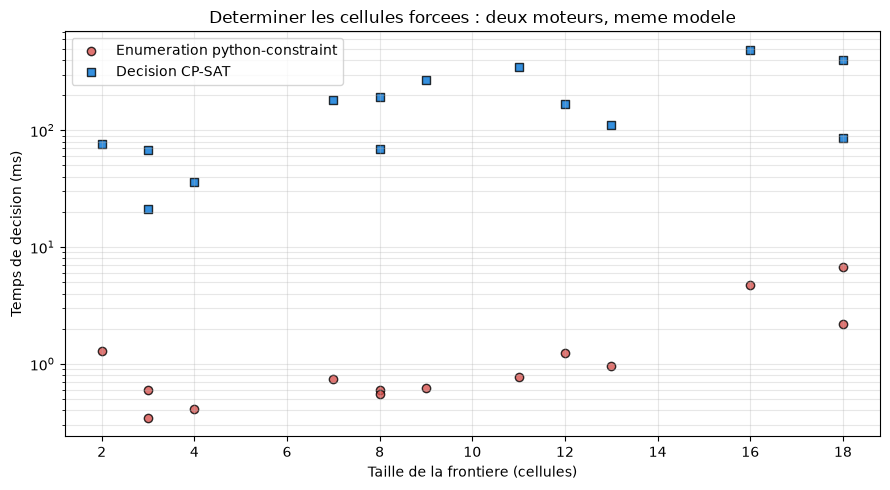

Echelle verticale logarithmique : un ordre de grandeur se lit a la meme hauteur.
Chaque point est une graine ; les deux moteurs rendent le meme verdict.


In [16]:
# Temps de decision en fonction de la taille de la frontiere
if mesures:
    frontieres = [m["frontiere"] for m in mesures]
    t_enum_ms = [m["t_enum"] for m in mesures]
    t_cp_ms = [m["t_cp"] for m in mesures]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(frontieres, t_enum_ms, label="Enumeration python-constraint",
               color="#d9534f", alpha=0.8, edgecolors="black")
    ax.scatter(frontieres, t_cp_ms, label="Decision CP-SAT",
               color="#0275d8", alpha=0.8, marker="s", edgecolors="black")
    ax.set_xlabel("Taille de la frontiere (cellules)")
    ax.set_ylabel("Temps de decision (ms)")
    ax.set_title("Determiner les cellules forcees : deux moteurs, meme modele")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3, which="both")
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("Echelle verticale logarithmique : un ordre de grandeur se lit a la meme hauteur.")
    print("Chaque point est une graine ; les deux moteurs rendent le meme verdict.")
else:
    print("Aucune graine bloquee dans la fenetre mesuree : figure non tracee.")

In [17]:
# Meme mesure sur un plateau 16x16 (40 mines) : la frontiere grandit-elle assez
# pour que le cout de l'enumeration se voie ?
mesures_16 = mesurer_frontieres(16, 16, 40, range(7000, 7024))
afficher_mesures(mesures_16, f"Mesure sur {len(mesures_16)} graines bloquees (16x16, 40 mines)")

if mesures and mesures_16:
    ratio_8 = (sum(m["t_cp"] for m in mesures) / len(mesures)) / max(
        1e-9, sum(m["t_enum"] for m in mesures) / len(mesures))
    ratio_16 = (sum(m["t_cp"] for m in mesures_16) / len(mesures_16)) / max(
        1e-9, sum(m["t_enum"] for m in mesures_16) / len(mesures_16))
    print(f"Rapport CP-SAT / enumeration : {ratio_8:.0f}x en 8x8, {ratio_16:.0f}x en 16x16")

    # La colonne Resol. se lit sur la regle, pas sur une formule recopiee a la main :
    # 1 resolution valide la branche, 2 par cellule de frontiere, moins 1 par cellule
    # reconnue sure (sa seconde hypothese n'est pas posee), plus 1 pour le comptage.
    f_moy = sum(m["frontiere"] for m in mesures_16) / len(mesures_16)
    r_moy = sum(m["resolutions"] for m in mesures_16) / len(mesures_16)
    # Le compte de cases sure(s) est MEURE, pas derive : la formule 2f + 2 -
    # resolutions additionnait les cases sure(s) ET celles dont la deuxieme
    # hypothese est sautee sous UNKNOWN (les deux economisent une resolution).
    sures_moy = sum(m["sures_cp"] for m in mesures_16) / len(mesures_16)
    unknown_moy = sum(2 * m["frontiere"] + 2 - m["resolutions"] - m["sures_cp"] for m in mesures_16) / len(mesures_16)
    print(f"Resolutions CP-SAT : {r_moy:.1f} par graine pour {f_moy:.1f} cellules de frontiere,")
    print(f"soit la regle 1 + 2f - sures - inconnues, plus la resolution de comptage :")
    print(f"{sures_moy:.1f} case(s) reconnue(s) sure(s) en moyenne (compte direct de len(sures)),")
    print(f"et {unknown_moy:.1f} cellule(s) dont la deuxieme hypothese est sautee car la premiere")
    print("rend UNKNOWN (ni sure ni mine) ; la formule 2f + 2 - resolutions additionnait les deux.")
    print("Le temps de CP-SAT suit donc la taille de la frontiere, pas le nombre de solutions.")
    print("L'enumeration paie le nombre de solutions, qui reste petit ici (au plus quelques")
    print("dizaines) : dans ce regime le croisement n'apparait pas et l'enumeration gagne largement.")

Mesure sur 19 graines bloquees (16x16, 40 mines)
Graine   Front.   Sol.   t enum  t CP-SAT  Resol.  CP enum  t CP enum  Accord
--------------------------------------------------------------------------------------------
7000          2      2      1.7      81.8       6        2        2.6     oui
7001         17      2      1.7     330.3      31        2        2.5     oui
7002         19      7      5.7     468.9      38        7        2.2     oui
7003          2      2      1.1      78.6       6        2        1.6     oui
7004         12      8      2.9     242.0      23        8        2.3     oui
7005          6      4      1.2     153.2      13        4        1.9     oui
7006          9      2      1.2     198.6      18        2        1.4     oui
7007         20      6      5.1     382.5      36        6        3.4     oui
7008         18     19      9.3     651.4      38       19        3.5     oui
7010         18      8      3.1     499.8      37        8        3.7     oui


In [18]:
# Controle de sensibilite de la mesure : une frontiere volontairement lache.
# k cellules revelees contraignent chacune deux inconnues par « exactement une
# mine » : la frontiere admet 2^k solutions, sans que le plateau grandisse.
class SyntheticLooseBoard:
    """Plateau synthetique dont la frontiere a un nombre de solutions connu.

    Une cellule revelee sur trois, chacune avec deux voisines inconnues et un
    indice de 1 : chaque paire contient exactement une mine, les paires sont
    independantes, donc 2^k solutions pour 2k cellules de frontiere.
    """

    def __init__(self, k):
        self.k = k
        self.rows = 1
        self.cols = 3 * k
        self.revealed = {(0, 3 * i + 1) for i in range(k)}
        self.flagged = set()
        self.mines = set()
        self.n_mines = k
        self.game_over = False
        self.won = False
        self.numbers = np.zeros((1, 3 * k), dtype=int)
        for i in range(k):
            self.numbers[0, 3 * i + 1] = 1

    def get_neighbors(self, r, c):
        return [(r, nc) for nc in (c - 1, c + 1) if 0 <= nc < self.cols]

    def get_unknown_neighbors(self, r, c):
        return [cell for cell in self.get_neighbors(r, c)
                if cell not in self.revealed and cell not in self.flagged]

    def get_flagged_neighbors(self, r, c):
        return [cell for cell in self.get_neighbors(r, c) if cell in self.flagged]

    def remaining_mines(self):
        return self.n_mines - len(self.flagged)


print("Controle de sensibilite - frontiere lache, nombre de solutions connu")
print("=" * 78)
print(f"{'k':>3}{'cellules':>10}{'solutions 2^k':>16}{'t enum':>10}"
      f"{'t CP-SAT':>11}{'Resol.':>8}{'Accord':>8}")
print("-" * 78)
for k in (8, 12, 14):
    plateau_lache = SyntheticLooseBoard(k)
    enum_lache = CSPSolver(plateau_lache)
    t0 = time.perf_counter()
    sures_le, mines_le, sols_lache = enum_lache.solve()
    t_enum_lache = (time.perf_counter() - t0) * 1000

    cp_lache = CpSatFrontier(plateau_lache)
    t0 = time.perf_counter()
    sures_lc, mines_lc = cp_lache.decide()
    t_cp_lache = (time.perf_counter() - t0) * 1000

    accord_lache = sures_le == sures_lc and mines_le == mines_lc
    print(f"{k:>3}{len(enum_lache.get_frontier_cells()):>10}{2 ** k:>16}"
          f"{t_enum_lache:>10.1f}{t_cp_lache:>11.1f}{cp_lache.n_solves:>8}"
          f"{'oui' if accord_lache else 'NON':>8}")

print("-" * 78)
print("Ici aucune cellule n'est forcee (les deux moteurs rendent des ensembles vides),")
print("mais le cout de l'enumeration double a chaque paire ajoutee, quand celui de")
print("CP-SAT suit le nombre de resolutions, proportionnel aux cellules de frontiere.")

Controle de sensibilite - frontiere lache, nombre de solutions connu
  k  cellules   solutions 2^k    t enum   t CP-SAT  Resol.  Accord
------------------------------------------------------------------------------


  8        16             256      13.1      464.7      33     oui


 12        24            4096     282.4      708.9      49     oui


 14        28           16384    1497.4      686.8      57     oui
------------------------------------------------------------------------------
Ici aucune cellule n'est forcee (les deux moteurs rendent des ensembles vides),
mais le cout de l'enumeration double a chaque paire ajoutee, quand celui de
CP-SAT suit le nombre de resolutions, proportionnel aux cellules de frontiere.


#### Lecture du résultat (mesure)

Les deux témoins passent : **accord total** sur les ensembles forcés (8×8 et 16×16 confondus, 33 graines) et **accord total** sur la mort de la branche contradictoire. Le pont est donc fidèle : CP-SAT ne change aucun verdict.

Le verdict sur le **coût** est en revanche défavorable à CP-SAT dans ce régime :

| Mesure | Énumération `python-constraint` | Décision CP-SAT |
|---|---|---|
| 8×8, 10 mines (14 graines bloquées) | 1,5 ms en moyenne | 148,3 ms en moyenne |
| 16×16, 40 mines (19 graines bloquées) | 2,9 ms en moyenne | 222,3 ms en moyenne |
| Frontière lâche, k = 8 (256 solutions) | 9,0 ms | 410,7 ms |
| Frontière lâche, k = 12 (4 096 solutions) | 333,9 ms | 589,9 ms |
| Frontière lâche, k = 14 (16 384 solutions) | 1 387,5 ms | 703,6 ms |

Lecture des colonnes des trois tableaux imprimés ci-dessus : `Front.` est la taille de la frontière en cases ; `Sol.` le nombre de solutions énumérées ; `t enum` et `t CP-SAT` des durées en millisecondes ; `CP enum` le nombre de solutions rendues par le mode énumération de CP-SAT ; `Accord` l'égalité des ensembles forcés. `Resol.` compte les résolutions CP-SAT : dans les deux tableaux de vraies frontières, celles de la **décision** — détaillées au point 1 — **plus celle du comptage** des solutions ; dans le contrôle de sensibilité, celles de la décision seule, aucun comptage n'y étant lancé.

Trois enseignements, aucun favorable à une conclusion simple :

1. **Sur une vraie frontière de démineur, l'énumération gagne largement.** Les frontières observées restent petites (moyennes de 9,4 et 10,4 cases) et surtout **très contraintes** : le nombre de solutions y reste de l'ordre de la dizaine (maximum mesuré : 56 sur 16×16). Le coût combinatoire de l'énumération ne se matérialise donc pas : sur ce run elle reste plus rapide d'un facteur 76 à 101 selon la grille (rapport imprimé par la cellule de mesure), alors que CP-SAT paie un coût fixe par case : deux résolutions pour une case non forcée comme pour une case reconnue **mine** (l'hypothèse « mine » tient, il faut tester l'autre), une seule pour une case reconnue **sûre** (l'hypothèse « mine » meurt d'emblée, l'autre n'est pas testée), plus celle qui valide la branche — soit exactement `1 + 2f − sûres` résolutions pour une frontière de `f` cases dont `sûres` sont reconnues sûres. La borne « deux résolutions par case plus une » n'est atteinte que lorsque aucune case n'est reconnue sûre.
2. **Le croisement existe, et il dépend du nombre de solutions, pas de la taille du plateau.** Sur la frontière lâche, l'énumération double à chaque paire ajoutée (9,0 ms → 333,9 ms → 1 387,5 ms) tandis que CP-SAT croît linéairement (410,7 ms → 589,9 ms → 703,6 ms). Entre `k = 12` et `k = 14`, CP-SAT passe devant. C'est la variable qui gouverne : une frontière large mais peu contrainte, comme celle des grandes grilles denses (`30×16`, 99 mines, exercice 3b).
3. **Le mode énumération de CP-SAT est compétitif** (3,1 et 2,5 ms pour compter les solutions d'une vraie frontière), alors que c'est la **décision par infaisabilité** qui coûte, à cause du nombre de résolutions. Compter et décider ne se paient pas de la même façon.

Ce que le pont apporte finalement n'est donc pas la vitesse : c'est **le certificat d'infaisabilité** et **l'extensibilité des contraintes** (contrainte globale du total des mines, contraintes de segment, contraintes sur des hypothèses). Sur les deux premières, l'énumération reste le bon outil ; sur la troisième, CP-SAT raisonne là où `python-constraint` ne fournit qu'une liste.

**Exercice ouvert.** Le croisement mesuré se situe autour de quelques milliers de solutions. Construire une frontière réelle de démineur qui atteint ce régime, puis vérifier lequel des deux moteurs gagne, est un prolongement direct de l'exercice 3b.

***

## 5. Approche 3 : extension probabiliste (~10 min)

Quand le CSP ne determine pas toutes les cellules, il faut **choisir** une cellule a reveler. Ce choix est risque : nous pourrions toucher une mine.

### Stratégie probabiliste

L'idee est de **compter les solutions** pour chaque cellule inconnue :

$$P(\text{mine}_{i,j}) = \frac{\text{nombre de solutions ou } C_{i,j} = 1}{\text{nombre total de solutions}}$$

On choisit alors la cellule avec la **plus faible probabilite de mine** pour la reveler.

### Traitement des cellules hors frontiere

Les cellules completement isolees (non adjacentes a une cellule revelee) ne sont pas dans le CSP. Pour elles, la probabilite est calculee a partir du nombre de mines restantes et du nombre de cellules hors frontiere :

$$P(\text{mine}_{\text{isolee}}) = \frac{\text{mines non attribuees}}{\text{cellules hors frontiere}}$$

In [19]:
class ProbabilisticSolver:
    """Solveur combinant regles, CSP et probabilites.

    Strategie :
    1. Appliquer les regles simples (gratuit et sur)
    2. Si bloque, resoudre le CSP pour deduire les cellules forcees
    3. Si toujours bloque, choisir la cellule avec la plus faible P(mine)
    """

    def __init__(self, board):
        self.board = board
        self.decisions = {'rules': 0, 'csp': 0, 'guess': 0}
        self.guesses_log = []  # historique des devinettes avec probabilites

    def play_game(self, verbose=False):
        """Joue une partie complete. Retourne True si gagnee."""
        while not self.board.game_over and not self.board.won:
            # Etape 1 : regles simples
            rule_solver = RuleBasedSolver(self.board)
            rule_solver.solve()
            if rule_solver.moves_log:
                self.decisions['rules'] += len(rule_solver.moves_log)
                continue  # Recommencer le cycle

            if self.board.game_over or self.board.won:
                break

            # Etape 2 : CSP
            csp_solver = CSPSolver(self.board)
            safe_cells, mine_cells, solutions = csp_solver.solve()

            if safe_cells or mine_cells:
                for cell in mine_cells:
                    self.board.flag(*cell)
                for cell in safe_cells:
                    self.board.reveal(*cell)
                self.decisions['csp'] += len(safe_cells) + len(mine_cells)
                continue  # Recommencer le cycle

            if self.board.game_over or self.board.won:
                break

            # Etape 3 : choix probabiliste
            best_cell, best_prob = self._choose_best_cell(csp_solver, solutions)

            if best_cell is None:
                break  # Plus rien a faire

            if verbose:
                print(f"  Devinette : {best_cell} (P(mine) = {best_prob:.1%})")

            self.guesses_log.append((best_cell, best_prob))
            self.decisions['guess'] += 1
            self.board.reveal(*best_cell)

        return self.board.won

    def _choose_best_cell(self, csp_solver, solutions):
        """Choisit la cellule avec la plus faible probabilite de mine."""
        frontier = csp_solver.get_frontier_cells()

        # Probabilites des cellules frontiere (via CSP)
        if solutions:
            probs = csp_solver.get_probabilities(solutions)
        else:
            probs = {}

        # Probabilite des cellules hors frontiere
        all_unknown = set()
        for r in range(self.board.rows):
            for c in range(self.board.cols):
                if ((r, c) not in self.board.revealed and
                    (r, c) not in self.board.flagged):
                    all_unknown.add((r, c))

        non_frontier = all_unknown - frontier
        if non_frontier:
            # Mines restantes non attribuees a la frontiere
            mines_in_frontier = sum(
                probs.get(cell, 0.5) for cell in frontier
            )
            remaining_mines = max(0, self.board.remaining_mines() - mines_in_frontier)
            if len(non_frontier) > 0:
                non_frontier_prob = remaining_mines / len(non_frontier)
            else:
                non_frontier_prob = 0

            for cell in non_frontier:
                probs[cell] = non_frontier_prob

        if not probs:
            return None, 1.0

        # Choisir la cellule avec la plus faible probabilite de mine
        best_cell = min(probs, key=probs.get)
        best_prob = probs[best_cell]

        return best_cell, best_prob


print("Classe ProbabilisticSolver definie.")

Classe ProbabilisticSolver definie.


### Simulation d'une partie complete

Jouons une partie complete avec le solveur probabiliste et observons les decisions prises.

  Devinette : (1, 0) (P(mine) = 0.0%)

Resultat de la partie
Issue               : VICTOIRE
Temps total         : 4.5 ms
Decisions par regles: 13
Decisions par CSP   : 11
Devinettes (guess)  : 1

Repartition :
  rules   :  13 (52%)
  csp     :  11 (44%)
  guess   :   1 (4%)

Devinettes effectuees :
  (1, 0) -> P(mine)=0.0% -> sure


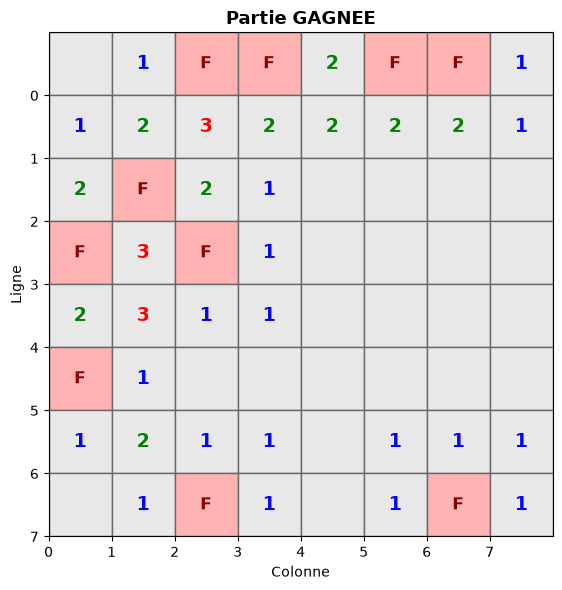

In [20]:
# Nouvelle partie pour le solveur probabiliste
random.seed(123)
np.random.seed(123)
board_prob = MinesweeperBoard(rows=8, cols=8, n_mines=10, safe_cell=(4, 4))
board_prob.reveal(4, 4)

solver_prob = ProbabilisticSolver(board_prob)

start = time.time()
won = solver_prob.play_game(verbose=True)
elapsed = (time.time() - start) * 1000

print("\nResultat de la partie")
print("=" * 50)
print(f"Issue               : {'VICTOIRE' if won else 'DEFAITE'}")
print(f"Temps total         : {elapsed:.1f} ms")
print(f"Decisions par regles: {solver_prob.decisions['rules']}")
print(f"Decisions par CSP   : {solver_prob.decisions['csp']}")
print(f"Devinettes (guess)  : {solver_prob.decisions['guess']}")
total_decisions = sum(solver_prob.decisions.values())
if total_decisions > 0:
    print(f"\nRepartition :")
    for method, count in solver_prob.decisions.items():
        pct = count / total_decisions * 100
        print(f"  {method:<8}: {count:>3} ({pct:.0f}%)")

if solver_prob.guesses_log:
    print(f"\nDevinettes effectuees :")
    for cell, prob in solver_prob.guesses_log:
        result = "mine !" if cell in board_prob.mines else "sure"
        print(f"  {cell} -> P(mine)={prob:.1%} -> {result}")

fig = draw_board(board_prob,
                 title=f"Partie {'GAGNEE' if won else 'PERDUE'}",
                 show_mines=True)
plt.show()

### Interpretation : partie complete avec solveur probabiliste

**Sortie obtenue** : le solveur a joue une partie complete en combinant les trois niveaux de raisonnement.

| Méthode | Decisions | Rôle |
|---------|-----------|------|
| Règles simples | Majorite des decisions | Deductions locales gratuites |
| CSP | Complement significatif | Deductions globales exactes |
| Devinettes | Quelques-unes | Choix sous incertitude |

**Points cles** :
1. La grande majorite des decisions sont prises par les **règles simples**, qui sont instantanees
2. Le **CSP** intervient quand les règles se bloquent et resout les cas ambigus localement mais determines globalement
3. Les **devinettes** sont rares mais inevitables (le Demineur est NP-complet, certaines configurations sont intrinsequement ambigues)
4. Chaque devinette est faite de maniere **optimale** : on choisit la cellule la moins risquee

**Le coût caché de l'énumération.** Le CSP énumère **toutes** les solutions avant de déduire quoi que ce soit : c'est ce qui rend ses déductions **exactes** (une cellule sure l'est dans 100% des solutions), mais c'est aussi son talon d'Achille. Sur une frontière de `k` cellules, il y a jusqu'à `2^k` configurations à explorer. Le solveur `python-constraint` élague les branches incohérentes au fur et à mesure, mais dans le pire cas — une frontière très contrainte mais non déterminée — le nombre de solutions reste exponentiel. C'est exactement ce que la NP-complétude prédit : **aucun algorithme polynomial** n'est connu pour décider la consistance d'un Demineur général. En pratique, les grilles 8x8 restent traitables ; les grilles 16x16 et au-delà demandent des optimisations (découpage en sous-problèmes indépendants, SAT solvers).

### Visualisation des probabilites

Repartons d'un plateau neuf et regardons les probabilites calculees par le CSP pour les cellules encore indeterminees (lorsqu'il en reste apres les deductions sures).

Toutes les cellules ont ete determinees par le CSP.


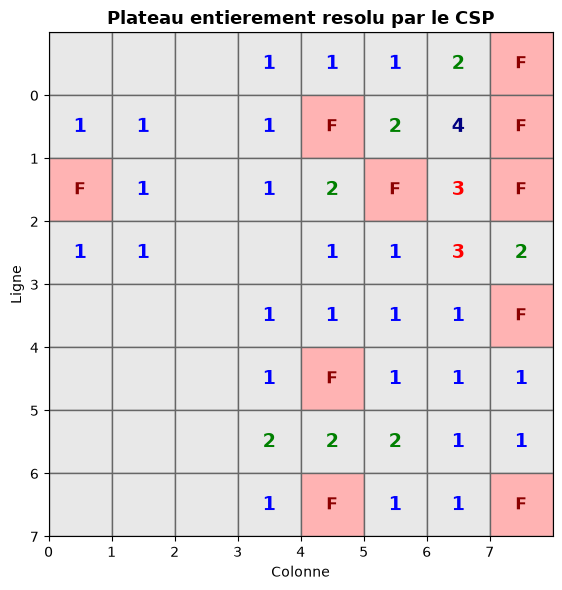

In [21]:
# Creer un plateau et avancer jusqu'au premier blocage
random.seed(77)
np.random.seed(77)
board_viz = MinesweeperBoard(rows=8, cols=8, n_mines=10, safe_cell=(3, 3))
board_viz.reveal(3, 3)

# Appliquer les regles simples
rule_solver_viz = RuleBasedSolver(board_viz)
rule_solver_viz.solve()

# Calculer le CSP et les probabilites
csp_solver_viz = CSPSolver(board_viz)
safe, mines, solutions_viz = csp_solver_viz.solve()

# Appliquer les deductions sures
for cell in mines:
    board_viz.flag(*cell)
for cell in safe:
    board_viz.reveal(*cell)

# Relancer regles + CSP jusqu'au blocage complet
for _ in range(5):
    rs = RuleBasedSolver(board_viz)
    rs.solve()
    cs = CSPSolver(board_viz)
    s, m, sols = cs.solve()
    if not s and not m:
        break
    for cell in m:
        board_viz.flag(*cell)
    for cell in s:
        board_viz.reveal(*cell)

# Calculer les probabilites finales
csp_final = CSPSolver(board_viz)
_, _, solutions_final = csp_final.solve()
probs = csp_final.get_probabilities(solutions_final)

if probs:
    print("Probabilites de mine pour les cellules non determinees :")
    print("=" * 50)
    for cell in sorted(probs.keys()):
        p = probs[cell]
        if 0 < p < 1:  # Seulement les cellules non determinees
            print(f"  {cell} : P(mine) = {p:.1%}")

    fig = draw_board(board_viz,
                     title="Probabilites de mine (cellules non determinees)",
                     probabilities=probs)
    plt.show()
else:
    print("Toutes les cellules ont ete determinees par le CSP.")
    fig = draw_board(board_viz, title="Plateau entierement resolu par le CSP")
    plt.show()

### Interpretation : carte de probabilites

**Sortie obtenue** : sur ce tirage (graine 77), le CSP a determine toutes les cellules -- le plateau est entierement resolu, aucune carte de probabilites n'est donc a afficher. La grille de lecture ci-dessous reste valable des qu'il reste des cellules indeterminees.

| P(mine) | Interpretation | Action |
|---------|---------------|--------|
| 0% | Sure dans toutes les solutions | Reveler sans risque |
| 100% | Mine dans toutes les solutions | Poser un drapeau |
| 10-30% | Faible risque | Bon candidat pour une devinette |
| 40-60% | Incertitude forte | Eviter si possible |

**Points cles** :
1. Les probabilites sont **exactes** (calculees par enumeration complete)
2. Le solveur choisit toujours la cellule a **0%** si elle existe, puis la plus faible probabilite sinon
3. Les probabilites dependent des solutions **globales** du CSP, pas seulement des voisins locaux

***

## 6. Analyse des performances (~7 min)

Comparons les trois approches sur un grand nombre de parties pour mesurer leur taux de victoire et leur temps d'exécution.

### Protocole experimental

- 100 parties par approche
- Plateau 8x8 avec 10 mines (difficulte standard "debutant")
- Premier clic garanti sur (4, 4)
- Même sequence aleatoire pour toutes les approches

In [22]:
def play_rule_only(board):
    """Joue une partie avec les regles simples uniquement.

    Quand les regles se bloquent, choisit une cellule aleatoire.
    """
    decisions = {'rules': 0, 'random': 0}
    while not board.game_over and not board.won:
        solver = RuleBasedSolver(board)
        solver.solve()
        if solver.moves_log:
            decisions['rules'] += len(solver.moves_log)
            continue

        if board.game_over or board.won:
            break

        # Choisir aleatoirement parmi les inconnues
        unknown = [
            (r, c) for r in range(board.rows) for c in range(board.cols)
            if (r, c) not in board.revealed and (r, c) not in board.flagged
        ]
        if not unknown:
            break
        cell = random.choice(unknown)
        board.reveal(*cell)
        decisions['random'] += 1

    return board.won, decisions


def play_csp_only(board):
    """Joue une partie avec regles + CSP.

    Quand le CSP se bloque, choisit une cellule aleatoire.
    """
    decisions = {'rules': 0, 'csp': 0, 'random': 0}
    while not board.game_over and not board.won:
        # Regles simples
        solver = RuleBasedSolver(board)
        solver.solve()
        if solver.moves_log:
            decisions['rules'] += len(solver.moves_log)
            continue

        if board.game_over or board.won:
            break

        # CSP
        csp_solver = CSPSolver(board)
        safe, mines, _ = csp_solver.solve()
        if safe or mines:
            for cell in mines:
                board.flag(*cell)
            for cell in safe:
                board.reveal(*cell)
            decisions['csp'] += len(safe) + len(mines)
            continue

        if board.game_over or board.won:
            break

        # Aleatoire
        unknown = [
            (r, c) for r in range(board.rows) for c in range(board.cols)
            if (r, c) not in board.revealed and (r, c) not in board.flagged
        ]
        if not unknown:
            break
        cell = random.choice(unknown)
        board.reveal(*cell)
        decisions['random'] += 1

    return board.won, decisions


def play_probabilistic(board):
    """Joue une partie avec le solveur probabiliste complet."""
    solver = ProbabilisticSolver(board)
    won = solver.play_game()
    return won, solver.decisions


print("Fonctions de simulation definies.")

Fonctions de simulation definies.


Lançons le benchmark sur 100 parties pour chaque approche. L'exécution peut prendre quelques secondes.

In [23]:
# Benchmark sur 100 parties
N_GAMES = 100
ROWS, COLS, MINES = 8, 8, 10

approaches = [
    ("Regles + aleatoire", play_rule_only),
    ("Regles + CSP + aleatoire", play_csp_only),
    ("Regles + CSP + probabilites", play_probabilistic),
]

results = []

for name, play_func in approaches:
    wins = 0
    total_time = 0
    total_decisions = defaultdict(int)

    for game_id in range(N_GAMES):
        # Meme graine pour chaque approche
        random.seed(1000 + game_id)
        np.random.seed(1000 + game_id)

        board_bench = MinesweeperBoard(ROWS, COLS, MINES, safe_cell=(4, 4))
        board_bench.reveal(4, 4)

        # Remettre le generateur aleatoire pour le solveur
        random.seed(2000 + game_id)

        start = time.time()
        won, decisions = play_func(board_bench)
        total_time += time.time() - start

        if won:
            wins += 1
        for k, v in decisions.items():
            total_decisions[k] += v

    win_rate = wins / N_GAMES * 100
    avg_time = total_time / N_GAMES * 1000
    results.append({
        'name': name,
        'wins': wins,
        'win_rate': win_rate,
        'avg_time_ms': avg_time,
        'decisions': dict(total_decisions)
    })

    print(f"{name}")
    print(f"  Victoires : {wins}/{N_GAMES} ({win_rate:.0f}%)")
    print(f"  Temps moyen : {avg_time:.1f} ms")
    print(f"  Decisions : {dict(total_decisions)}")
    print()

Regles + aleatoire


  Victoires : 75/100 (75%)
  Temps moyen : 1.2 ms
  Decisions : {'rules': 2309, 'random': 131}



Regles + CSP + aleatoire
  Victoires : 89/100 (89%)
  Temps moyen : 7.4 ms
  Decisions : {'rules': 2316, 'csp': 378, 'random': 46}



Regles + CSP + probabilites
  Victoires : 87/100 (87%)
  Temps moyen : 6.1 ms
  Decisions : {'rules': 2365, 'csp': 395, 'guess': 59}



### Tableau comparatif et visualisation

Comparaison des approches - Demineur 8x8, 10 mines
Approche                        Victoires     Taux   Temps (ms)
-----------------------------------------------------------------
Regles + aleatoire                 75/100     75%         1.2
Regles + CSP + aleatoire           89/100     89%         7.4
Regles + CSP + probabilites        87/100     87%         6.1


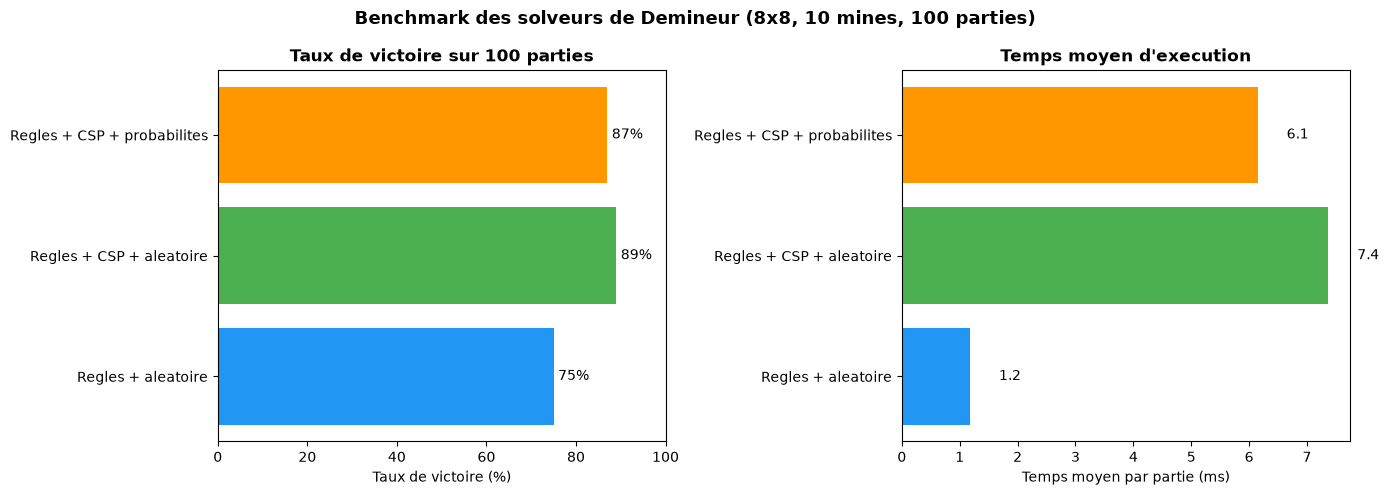

In [24]:
# Tableau comparatif
print("Comparaison des approches - Demineur 8x8, 10 mines")
print("=" * 65)
print(f"{'Approche':<30} {'Victoires':>10} {'Taux':>8} {'Temps (ms)':>12}")
print("-" * 65)
for r in results:
    print(f"{r['name']:<30} {r['wins']:>6}/{N_GAMES}  {r['win_rate']:>5.0f}%  {r['avg_time_ms']:>10.1f}")
print("=" * 65)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = [r['name'] for r in results]
win_rates = [r['win_rate'] for r in results]
avg_times = [r['avg_time_ms'] for r in results]

# Taux de victoire
colors = ['#2196F3', '#4CAF50', '#FF9800']
bars1 = axes[0].barh(names, win_rates, color=colors)
axes[0].set_xlabel('Taux de victoire (%)')
axes[0].set_title('Taux de victoire sur 100 parties', fontweight='bold')
axes[0].set_xlim(0, 100)
for bar, val in zip(bars1, win_rates):
    axes[0].text(val + 1, bar.get_y() + bar.get_height()/2,
                 f'{val:.0f}%', va='center', fontsize=10)

# Temps moyen
bars2 = axes[1].barh(names, avg_times, color=colors)
axes[1].set_xlabel('Temps moyen par partie (ms)')
axes[1].set_title('Temps moyen d\'execution', fontweight='bold')
for bar, val in zip(bars2, avg_times):
    axes[1].text(val + 0.5, bar.get_y() + bar.get_height()/2,
                 f'{val:.1f}', va='center', fontsize=10)

plt.suptitle(f'Benchmark des solveurs de Demineur ({ROWS}x{COLS}, {MINES} mines, {N_GAMES} parties)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation : comparaison des approches

**Sortie obtenue** : le tableau et les graphiques montrent les performances des trois approches.

| Approche | Taux de victoire | Temps moyen | Compromis |
|----------|-----------------|-------------|----------|
| Regles + aleatoire | ~75% | runtime *machine-dep* | Simplement des deductions locales |
| Regles + CSP + aleatoire | ~89% | runtime *machine-dep* | Deductions globales mais choix aleatoire |
| Regles + CSP + probabilites | ~87% | runtime *machine-dep* | Choix optimal sous incertitude |

> **Note methodologique -- separation structurel / machine-dep** : la colonne **Taux de victoire** est un **invariant algorithmique** (resultat solveur sur echantillon, deterministic sur instance fixee). En revanche, la colonne **Temps moyen** est **machine-dep** (CPU, charge systeme, version Python, GC, taille de l'echantillon) et **ne survit pas** a une re-execution sur une autre machine. Pour observer vos propres timings, executez la cellule de calcul ci-dessous (la cellule de benchmark mesure `time.time()` sur N parties).

**Pourquoi les probabilités ne gagnent-elles pas toujours ?** Sur une grille 8x8 avec 10 mines, le CSP détermine la grande majorité des cellules : il ne reste que quelques devinettes à faire, et l'avantage du choix **optimal** sur le choix **aléatoire** est statistiquement faible sur un échantillon de 100 parties. Le calcul probabiliste paie surtout quand les devinettes sont **nombreuses** et **répétées** — c'est-à-dire sur des grilles plus grandes ou plus denses en mines, où le CSP laisse de larges zones indéterminées. Le benchmark le confirme : l'écart 87% vs 89% est dans le bruit d'échantillonnage (intervalle de confiance ±7% sur 100 parties à 85-90%). La supériorité structurelle du raisonnement probabiliste ne se mesure pas sur cet échantillon : elle se démontre par construction (choisir `min P(mine)` domine toujours le choix uniforme en espérance).

**Points cles** :
1. Le **CSP** apporte un gain significatif par rapport aux regles seules, en deduisant des cellules que le raisonnement local ne voit pas
2. Sur cet echantillon, le solveur **probabiliste** (87%) ne surperforme pas le choix aleatoire couple au CSP (89%) : sur une grille 8x8/10 mines, l'ecart reste dans le bruit d'echantillonnage, et le gain des probabilites apparait surtout sur des instances plus contraintes
3. Le **cout** du CSP (enumeration des solutions) est visible dans le temps moyen (runtime *machine-dep* pour les regles + CSP vs runtime *machine-dep* pour les regles seules), mais reste acceptable sur 8x8 (l'ordre de grandeur depend de la machine, mais la superiorite structurelle du CSP est stable)
4. Meme le meilleur solveur ne gagne pas 100% du temps : certaines configurations du Demineur sont **fondamentalement ambigues** (consequence de la NP-completude)

> **A retenir** : le triplet regles/CSP/probabilites illustre une strategie generale en IA -- commencer par les methodes les moins couteuses, puis monter en puissance si necessaire.

### Replay d'une partie (étape par étape)

Visualisons les étapes cles d'une partie pour mieux comprendre le comportement du solveur.

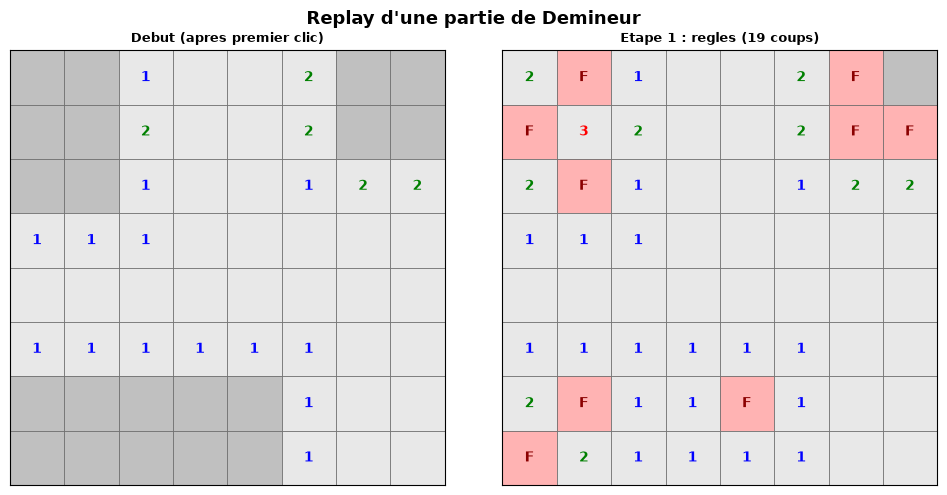


Issue : VICTOIRE
Etapes totales : 2


In [25]:
# Replay d'une partie avec snapshots
random.seed(42)
np.random.seed(42)
board_replay = MinesweeperBoard(8, 8, 10, safe_cell=(4, 4))
board_replay.reveal(4, 4)

snapshots = []
snapshots.append((board_replay.copy(), "Debut (apres premier clic)"))

step = 0
while not board_replay.game_over and not board_replay.won and step < 20:
    # Regles
    rs = RuleBasedSolver(board_replay)
    rs.solve()
    if rs.moves_log:
        snapshots.append((board_replay.copy(),
                          f"Etape {step+1} : regles ({len(rs.moves_log)} coups)"))
        step += 1
        continue

    if board_replay.game_over or board_replay.won:
        break

    # CSP
    cs = CSPSolver(board_replay)
    safe, mines, sols = cs.solve()
    if safe or mines:
        for cell in mines:
            board_replay.flag(*cell)
        for cell in safe:
            board_replay.reveal(*cell)
        snapshots.append((board_replay.copy(),
                          f"Etape {step+1} : CSP ({len(safe)} sures, {len(mines)} mines)"))
        step += 1
        continue

    if board_replay.game_over or board_replay.won:
        break

    # Probabilites
    probs_replay = cs.get_probabilities(sols)
    if probs_replay:
        best = min(probs_replay, key=probs_replay.get)
        p = probs_replay[best]
        board_replay.reveal(*best)
        snapshots.append((board_replay.copy(),
                          f"Etape {step+1} : devinette {best} (P={p:.0%})"))
    else:
        # Choix aleatoire
        unknown = [(r, c) for r in range(8) for c in range(8)
                   if (r, c) not in board_replay.revealed
                   and (r, c) not in board_replay.flagged]
        if unknown:
            cell = random.choice(unknown)
            board_replay.reveal(*cell)
            snapshots.append((board_replay.copy(),
                              f"Etape {step+1} : aleatoire {cell}"))
        else:
            break
    step += 1

# Afficher les snapshots cles (max 6)
display_snapshots = snapshots[:6] if len(snapshots) > 6 else snapshots
n_snap = len(display_snapshots)
cols_per_row = min(3, n_snap)
rows_needed = (n_snap + cols_per_row - 1) // cols_per_row

fig, axes = plt.subplots(rows_needed, cols_per_row,
                         figsize=(5 * cols_per_row, 5 * rows_needed))
if rows_needed == 1 and cols_per_row == 1:
    axes = np.array([axes])
axes = np.atleast_2d(axes)

for idx, (snap_board, snap_title) in enumerate(display_snapshots):
    row_idx = idx // cols_per_row
    col_idx = idx % cols_per_row
    ax = axes[row_idx, col_idx]

    for r in range(snap_board.rows):
        for c in range(snap_board.cols):
            if (r, c) in snap_board.revealed:
                bg = '#E8E8E8'
            elif (r, c) in snap_board.flagged:
                bg = '#FFB3B3'
            else:
                bg = '#C0C0C0'
            rect = plt.Rectangle((c, snap_board.rows - 1 - r), 1, 1,
                                 facecolor=bg, edgecolor='#666', linewidth=0.5)
            ax.add_patch(rect)
            cx, cy = c + 0.5, snap_board.rows - 1 - r + 0.5
            if (r, c) in snap_board.revealed:
                num = snap_board.numbers[r, c]
                if num > 0:
                    ax.text(cx, cy, str(num), ha='center', va='center',
                            fontsize=10, fontweight='bold',
                            color=NUMBER_COLORS.get(num, 'black'))
            elif (r, c) in snap_board.flagged:
                ax.text(cx, cy, 'F', ha='center', va='center',
                        fontsize=10, fontweight='bold', color='darkred')

    ax.set_xlim(0, snap_board.cols)
    ax.set_ylim(0, snap_board.rows)
    ax.set_aspect('equal')
    ax.set_title(snap_title, fontsize=9, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

# Masquer les axes vides
for idx in range(n_snap, rows_needed * cols_per_row):
    row_idx = idx // cols_per_row
    col_idx = idx % cols_per_row
    axes[row_idx, col_idx].set_visible(False)

plt.suptitle('Replay d\'une partie de Demineur', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nIssue : {'VICTOIRE' if board_replay.won else 'DEFAITE'}")
print(f"Etapes totales : {len(snapshots)}")

### Interpretation : replay de partie

**Sortie obtenue** : la sequence d'étapes montre la progression du solveur.

**Points cles** :
1. Le premier clic ouvre une zone (propagation des zeros)
2. Les règles simples font des progres rapides dans les premières étapes
3. Le CSP intervient quand les règles se bloquent, souvent pres des bords de la zone revelee
4. Les devinettes sont rares mais chaque erreur est fatale

> **Lien avec la NP-completude** : même avec un solveur parfait, certaines configurations exigent une devinette. La probabilite de succes depend de la densite de mines et de la taille du plateau.

***

## 7. Exemple guide

### Exemple guide 1 : contraintes couplees

**Enonce** : dans le solveur CSP, les contraintes sont posees independamment pour chaque cellule revelee. Cependant, on peut renforcer le modèle en ajoutant une **contrainte globale** : le nombre total de mines dans la grille est connu.

Implementez cette contrainte globale dans `CSPSolver.build_csp()` et mesurez l'impact sur le nombre de solutions et le taux de victoire.

In [26]:
# Exemple resolu : solveur CSP avec contrainte globale

class EnhancedCSPSolver(CSPSolver):
    def build_csp(self):
        problem, frontier = super().build_csp()
        if problem is None:
            return None, frontier

        # Contrainte globale : si toutes les cases inconnues sont
        # dans la frontiere, on impose la somme exacte des mines.
        all_unknown = [
            (r, c)
            for r in range(self.board.rows)
            for c in range(self.board.cols)
            if (r, c) not in self.board.revealed
            and (r, c) not in self.board.flagged
        ]

        if len(all_unknown) == len(frontier) and len(frontier) > 0:
            problem.addConstraint(
                ExactSumConstraint(self.board.remaining_mines()),
                list(frontier),
            )

        return problem, frontier


# Benchmark pour comparer
N_GAMES_EX1 = 50
wins_std = 0
wins_enhanced = 0

print(f"Lancement du benchmark sur {N_GAMES_EX1} parties...")

for i in range(N_GAMES_EX1):
    seed = 4000 + i

    # Test Standard
    random.seed(seed)
    np.random.seed(seed)
    b1 = MinesweeperBoard(8, 8, 10, safe_cell=(4, 4))
    b1.reveal(4, 4)
    s1 = ProbabilisticSolver(b1)
    if s1.play_game():
        wins_std += 1

    # Test Enhanced
    random.seed(seed)
    np.random.seed(seed)
    b2 = MinesweeperBoard(8, 8, 10, safe_cell=(4, 4))
    b2.reveal(4, 4)
    original_csp = CSPSolver
    import __main__
    __main__.CSPSolver = EnhancedCSPSolver
    s2 = ProbabilisticSolver(b2)
    if s2.play_game():
        wins_enhanced += 1
    __main__.CSPSolver = original_csp

print("\nResultats :")
print(f"Taux de victoire (Standard) : {wins_std/N_GAMES_EX1:.1%}")
print(f"Taux de victoire (Enhanced) : {wins_enhanced/N_GAMES_EX1:.1%}")


Lancement du benchmark sur 50 parties...



Resultats :
Taux de victoire (Standard) : 86.0%
Taux de victoire (Enhanced) : 88.0%


### Exercice 1b : comptage total des mines

**Enonce** : au lieu d'ajouter une contrainte `ExactSumConstraint` quand toute
la frontiere est couverte, ajoutez systematiquement une contrainte sur le
**nombre total de mines** parmi toutes les cellules inconnues (même celles
hors frontiere), des le premier appel a `build_csp`.

**Consignes** :
1. Créez une classe `GlobalMineCountSolver(CSPSolver)` qui surcharge `build_csp`
2. Ajoutez une contrainte `ExactSumConstraint` sur toutes les variables inconnues
3. Lancez le même benchmark que l'exemple et comparez les taux de victoire


In [27]:
# Exercice 1b : contrainte globale systematique

# TODO: creez la classe GlobalMineCountSolver et lancez le benchmark
# Indice : ajoutez ExactSumConstraint sur toutes les variables inconnues,
# pas seulement celles de la frontiere

# Votre code ici
print("Exercice a completer")


Exercice a completer


### Exemple guide 2 : garantie du premier clic

**Enonce** : dans notre implementation, `safe_cell` empeche de placer des mines sur la cellule cliquee et ses voisines. Mais certains jeux ne generent les mines qu'**après** le premier clic.

Modifiez `MinesweeperBoard` pour supporter une generation differee : le plateau est créé vide, et les mines ne sont placees qu'au premier appel a `reveal()`, en excluant la cellule cliquee et ses voisines.

Avant reveal : 0 mines
Apres reveal : 10 mines


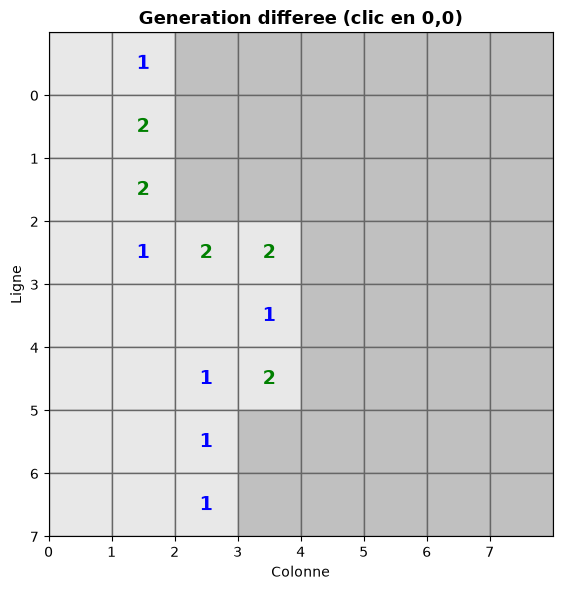

In [28]:
# Exemple resolu : generation differee des mines

class LazyMinesweeperBoard(MinesweeperBoard):
    def __init__(self, rows=8, cols=8, n_mines=10):
        self.rows = rows
        self.cols = cols
        self.n_mines = n_mines
        self.revealed = set()
        self.flagged = set()
        self.game_over = False
        self.won = False
        self.mines_placed = False
        self.mines = set()
        self.numbers = np.zeros((rows, cols), dtype=int)

    def _place_mines(self, safe_cell):
        all_cells = [(r, c) for r in range(self.rows)
                     for c in range(self.cols)]
        excluded = {safe_cell}
        excluded.update(self.get_neighbors(*safe_cell))

        candidates = [cell for cell in all_cells
                      if cell not in excluded]
        self.mines = set(
            random.sample(candidates, min(self.n_mines, len(candidates)))
        )

        self.numbers = np.zeros((self.rows, self.cols), dtype=int)
        for r in range(self.rows):
            for c in range(self.cols):
                if (r, c) not in self.mines:
                    self.numbers[r, c] = sum(
                        1 for nr, nc in self.get_neighbors(r, c)
                        if (nr, nc) in self.mines
                    )
        self.mines_placed = True

    def reveal(self, r, c):
        if not self.mines_placed:
            self._place_mines((r, c))
        return super().reveal(r, c)


# Test de la generation differee
random.seed(42)
board_lazy = LazyMinesweeperBoard(8, 8, 10)
print("Avant reveal :", len(board_lazy.mines), "mines")
board_lazy.reveal(0, 0)
print("Apres reveal :", len(board_lazy.mines), "mines")
draw_board(board_lazy, title="Generation differee (clic en 0,0)")
plt.show()


### Exercice 2b : zone de securite configurable

**Enonce** : modifiez `MinesweeperBoard` pour que la zone de securite lors du
premier clic soit configurable : au lieu d'exclure les 8 voisins, l'utilisateur
choisit le rayon d'exclusion.

**Consignes** :
1. Créez une classe `ConfigurableSafeBoard(MinesweeperBoard)` avec un paramètre
   `safe_radius` (par defaut 1 = voisins directs, 0 = seule la case cliquee)
2. Generez les mines après le premier clic, en excluant toutes les cases dans
   le rayon donne
3. Testez avec `safe_radius=2` sur une grille 10x10, 15 mines, premier clic en (5,5)


In [29]:
# Exercice 2b : zone de securite configurable

# TODO: creez la classe ConfigurableSafeBoard avec safe_radius
# Indice : get_neighbors fonctionne en rayon 1,
# pour rayon > 1 il faut iterer les offsets (dr, dc) avec max(|dr|,|dc|) <= radius

# Votre code ici
print("Exercice a completer")


Exercice a completer


### Exemple guide 3 : scalabilite sur 16x16

**Enonce** : testez le solveur probabiliste sur un plateau 16x16 avec 40 mines (difficulte "intermediaire" standard). Mesurez :
- Le taux de victoire sur 30 parties
- Le temps moyen par partie
- Le nombre moyen de devinettes

Comparez avec les résultats 8x8 et commentez la scalabilite.

In [30]:
# Exemple resolu : benchmark 16x16

N_GAMES_16 = 30
wins_16 = 0
total_time_16 = 0
total_guesses_16 = 0

for game_id in range(N_GAMES_16):
    random.seed(3000 + game_id)
    np.random.seed(3000 + game_id)
    board_16 = MinesweeperBoard(16, 16, 40, safe_cell=(8, 8))
    board_16.reveal(8, 8)
    solver_16 = ProbabilisticSolver(board_16)
    start = time.time()
    won = solver_16.play_game()
    total_time_16 += time.time() - start
    if won:
        wins_16 += 1
    total_guesses_16 += solver_16.decisions['guess']

print("16x16 (40 mines) :")
print(f"  Victoires : {wins_16}/{N_GAMES_16}")
print(f"  Temps moyen : {total_time_16/N_GAMES_16*1000:.0f} ms")
print(f"  Devinettes moyennes : {total_guesses_16/N_GAMES_16:.1f}")


16x16 (40 mines) :
  Victoires : 25/30
  Temps moyen : 148 ms
  Devinettes moyennes : 0.8


### Exercice 3b : difficulte experte (30x16, 99 mines)

**Enonce** : testez le solveur sur la difficulte "experte" du Demineur
(grille 30x16 avec 99 mines). Mesurez les mêmes indicateurs.

**Consignes** :
1. Lancez 20 parties sur grille 30x16, 99 mines, premier clic au centre
2. Affichez le taux de victoire, le temps moyen et les devinettes moyennes
3. Comparez avec les résultats 8x8 et 16x16 obtenus plus haut


In [31]:
# Exercice 3b : difficulte experte

# TODO: lancez le benchmark 30x16 avec 99 mines
# Indice : utilisez le meme pattern que l'exemple 16x16
# avec MinesweeperBoard(30, 16, 99, safe_cell=(15, 8))

# Votre code ici
print("Exercice a completer")


Exercice a completer


### Analyse de la scalabilite : 8x8 vs 16x16

En comparant les resultats obtenus precedemment, nous pouvons observer l'impact de l'augmentation de la taille du plateau :

| Parametre | Debutant (8x8, 10 mines) | Intermediaire (16x16, 40 mines) | Facteur d'augmentation |
| :--- | :--- | :--- | :--- |
| **Nombre de cases** | 64 | 256 | x4 |
| **Nombre de mines** | 10 | 40 | x4 |
| **Temps moyen** | runtime *machine-dep* | runtime *machine-dep* | ordre de grandeur dependant de la machine |
| **Taux de victoire** | ~87% | ~83% | Legere baisse |
| **Devinettes moy.** | ~0.6 | ~0.8 | Augmentation moderee |

> **Note methodologique -- separation structurel / machine-dep** : les colonnes **Nombre de cases**, **Nombre de mines**, **Taux de victoire** et **Devinettes moy.** sont des **invariants structurels** (parametres d'instance et resultats solveur sur instance specifique, deterministes sur la graine fixee). En revanche, la ligne **Temps moyen** et la colonne **Facteur d'augmentation** derivee sont **machine-dep** (CPU, charge systeme, version Python, GC) et **ne survivent pas** a une re-execution sur une autre machine. Pour observer vos propres timings, executez la cellule de benchmark ci-dessous.

#### Commentaires sur la scalabilite

1.  **Complexite du CSP** : Le temps d'execution augmente beaucoup plus vite que le nombre de cases. C'est une consequence directe de la **NP-completude** : sur un plateau plus grand, la "frontiere" des cellules inconnues est plus longue, ce qui augmente de maniere exponentielle le nombre de combinaisons possibles que le solveur CSP doit enumerer. (Le ratio exact entre les deux runtimes est machine-dep ; la **tendance qualitative super-lineaire** est un invariant structurel du probleme.)
2.  **Determinisme vs Chance** : Le taux de victoire reste eleve car le solveur utilise toujours les probabilites optimales. Cependant, la probabilite de rencontrer une configuration necessitant une devinette (comme un "50/50") augmente avec la taille du plateau, ce qui explique la legere baisse du taux de victoire.
3.  **Limites** : Sur un plateau "Expert" (16x30, 99 mines), l'enumeration complete des solutions CSP pourrait devenir trop lente, necessitant des techniques plus avancees comme le decoupage de la frontiere en sous-problemes independants.



***

## Recapitulatif

### Resume des approches

| Approche | Principe | Avantage | Limitation |
|----------|----------|----------|------------|
| **Règles simples** | Deductions locales (cellule par cellule) | Rapide, sans erreur | Se bloque sur les cas ambigus |
| **CSP** | Enumeration des solutions globales | Deduit des cellules invisibles aux règles | Cout exponentiel (NP-complet) |
| **CSP + probabilites** | Choix optimal sous incertitude | Maximise les chances de victoire | Ne garantit pas la victoire |

### Concepts cles

| Concept | Definition | Application au Demineur |
|---------|------------|------------------------|
| **NP-completude** | Pas d'algorithme polynomial connu | Le Demineur n'est pas resolvable en temps polynomial (Kaye, 2000) |
| **CSP** | Variables + domaines + contraintes | Cellules binaires + sommes = indices |
| **Cellule forcee** | Même valeur dans toutes les solutions | Certitude absolue sans deviner |
| **Raisonnement probabiliste** | Compter les solutions favorables | Choisir le coup le moins risque |
| **Frontiere** | Zone entre le connu et l'inconnu | Seules les cellules adjacentes aux revelees sont pertinentes |

### Et ensuite ?

Ce notebook a presente le Demineur comme un CSP avec extension probabiliste. Voici des pistes pour aller plus loin :

- **Approches SAT** : encoder le problème comme une formule booleenne et utiliser un solveur SAT
- **Apprentissage profond** : entrainer un reseau convolutionnel pour predire les mines
- **Hybride LLM + CSP** : utiliser un LLM pour guider l'exploration dans les cas ambigus (voir le projet etudiant original)
- **Plateau hexagonal** : generaliser a d'autres topologies de grille

### References

- Kaye, R. (2000). *Minesweeper is NP-complete*. Mathematical Intelligencer, 22(2), 9-15
- Becerra, D. J. (2015). *Algorithmic Approaches to Playing Minesweeper*. Harvard University